# Project Machine Learning: Klasifikasi Kategori Berita
## Notebook Berkelanjutan — Mikroskil

**Kelompok:** Project Berita

**Project ID:** A13

| Nama | NIM |
|---|---|
| Matthew Rivandy | 231111820 |
| Oktapianus Zalukhu | 231111267 |
| Afni Titus Simanjuntak | 231111841 |

Notebook ini digunakan secara berkelanjutan sampai UTS dan UAS. ...

Notebook ini digunakan secara berkelanjutan sampai UTS dan UAS. ...
Notebook ini digunakan secara berkelanjutan sampai UTS dan UAS. Dataset dimuat langsung dari URL, sehingga notebook dapat dijalankan dari awal sampai akhir di Google Colab tanpa upload file manual.

**Cara menjalankan:** buka di Google Colab, pilih *Runtime → Run all*. Semua pembagian data dan model memakai `random_state=42`. Seluruh proses memerlukan waktu sekitar 20–30 menit karena ada beberapa cross-validation dan t-SNE. Berkas hasil (`hasil_*.csv`, `TABEL_PERBANDINGAN_MODEL.csv`, `perbandingan_per_kelas.csv`, `hasil_fitur_tambahan.csv`) tersimpan di folder kerja Colab.

**Cakupan UTS (Milestone 1):** Bagian 1, Bagian 2, dan Bagian 3. Pertemuan 5–7 adalah eksplorasi tambahan di luar cakupan UTS.

**Riwayat pertemuan:**
- Minggu 1-2 (Task 02): Project Identification → Preprocessing Plan → Initial Feature Engineering → Initial Data Pipeline
- Minggu 3: Baseline Model & Evaluasi Awal (Text Mining)
- Minggu 4: Kandidat Model & Perbandingan dengan Baseline
- Minggu 5-7: Validasi & kestabilan, unsupervised learning, feature selection, diagnosis, error analysis (eksplorasi tambahan)

**Peta komponen laporan UTS terhadap notebook:**

| Komponen laporan | Lokasi di notebook |
|---|---|
| A. Problem formulation | Bagian 1 §2, Bagian 2 A |
| B. Dataset dan data understanding | Bagian 1 §3, §4, §6 |
| C. EDA dan initial findings | Bagian 1 §5 (termasuk EDA tambahan) |
| D. Preprocessing | Bagian 1 §7, Bagian 2 C |
| E. Initial feature engineering | Bagian 1 §8, Bagian 3 D2 |
| F. Baseline dan model kandidat | Bagian 2 D, Bagian 3 A–C |
| G. Evaluation design | Bagian 2 E |
| H. Initial results and analysis | Bagian 3 D–H |
| I. Documentation and next plan | Bagian 3 I, bagian ini |

# BAGIAN 1 — PROJECT TASK 02: DATA UNDERSTANDING & PERSIAPAN DATA (Bagian Matthew RIvandy)

## 1. Project Identification
| Informasi | Keterangan |
|---|---|
| Judul project | Klasifikasi Kategori Berita Berbahasa Indonesia |
| Topik | Berita |
| Jenis tugas ML | Klasifikasi teks multi-kelas (Text Mining) |
| Anggota kelompok | Matthew Rivandy, Oktapianus Zalukhu, Afni Titus Simanjuntak [lengkapi bila ada anggota lain] |

## 2. Problem Formulation
- **Latar belakang:** Portal berita online menerbitkan ribuan artikel setiap hari dan pengelompokan kategori secara manual memakan waktu serta rawan tidak konsisten.
- **Rumusan masalah:** Bagaimana memprediksi kategori sebuah berita hanya dari judulnya?
- **Tujuan:** Menyiapkan data, fitur, dan model baseline untuk klasifikasi kategori berita otomatis, lalu membandingkan model kandidat dengan baseline secara adil.
- **Target (label):** kolom `category` (9 kelas).
- **Pendekatan ML:** classification multi-kelas pada teks (classical machine learning: TF-IDF + model linear/probabilistik), sesuai batasan Milestone 1.
- **Target analisis:** sebuah model kandidat dianggap lebih baik dari baseline bila macro-F1 pada cross-validation lebih tinggi secara konsisten (selisih lebih besar dari variasi antar-fold dan menang pada fold yang sama), lalu dikonfirmasi pada data uji.
- **Batasan proyek:** (1) hanya memakai judul, bukan isi artikel; (2) data satu sumber (detik.com) periode Januari–Juni 2020; (3) label adalah kanal/rubrik publikasi, bukan anotasi topik murni; (4) hanya classical machine learning; (5) kolom `url` tidak boleh dipakai karena membocorkan label (lihat bagian 6).
- **Manfaat:** Mempercepat pengelompokan artikel, mendukung rekomendasi/pencarian berita berdasarkan kategori.

## 3. Dataset dan Sumber
| Informasi | Keterangan |
|---|---|
| Nama dataset | Indonesian News Title Dataset |
| Sumber | detik.com, dikumpulkan oleh ibamibrahim (GitHub) |
| Link sumber | https://github.com/ibamibrahim/dataset-judul-berita-indonesia |
| Unit observasi | 1 baris = 1 judul berita detik.com |
| Jumlah baris | 91.017 |
| Jumlah kolom | 4 (date, url, title, category) |
| Deskripsi kolom | `date`: tanggal terbit (format bulan/hari/tahun); `url`: tautan artikel (bernilai `#` untuk kategori `inet`); `title`: judul berita; `category`: kanal/rubrik detik.com |
| Variabel utama | title (teks judul berita) |
| Target | category: finance, food, health, hot, inet, news, oto, sport, travel (9 kelas) |
| Jenis data | Teks (title), Kategorikal (category), Tanggal (date), URL (url) |
| Periode data | 1 Januari – 13 Juni 2020 (diverifikasi pada bagian 4.1b) |
| Lisensi / keterangan penggunaan | Dataset publik di GitHub; cantumkan sumber saat dipakai (lisensi formal belum diperiksa kelompok) |

**Alasan dataset sesuai:** sumber jelas (repository publik di GitHub), deskripsi kolom dapat dipahami, variabel `title` relevan dengan tujuan klasifikasi, jumlah data besar (91 ribu baris) dan ada 9 kategori sebagai label.

**Masalah kualitas data yang ditemukan:** ketidakseimbangan kelas (13,3 : 1), judul duplikat termasuk 29 judul berlabel konflik, kolom `url` yang membocorkan label, dan dominasi tema COVID-19 pada periode tertentu (rincian pada bagian 4.1b dan 6).

In [ ]:
import re
import warnings
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ====== KONFIGURASI ======
# Dataset dimuat langsung dari GitHub, tidak perlu upload manual.
DATA_PATH = "https://raw.githubusercontent.com/ibamibrahim/dataset-judul-berita-indonesia/master/detik_news_title.csv"
TEXT_COL  = "title"     # kolom judul berita
LABEL_COL = "category"  # kolom kategori (target)
# ==========================

df = pd.read_csv(DATA_PATH)
df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)
print("Jumlah baris, kolom:", df.shape)
df.head()

Jumlah baris, kolom: (91017, 4)


,date,url,title,category
0,02/26/2020,https://finance.detik.com/berita-ekonomi-bisni...,Kemnaker Awasi TKA di Meikarta,finance
1,02/26/2020,https://finance.detik.com/berita-ekonomi-bisni...,BNI Digitalkan BNI Java Jazz 2020,finance
2,02/26/2020,https://finance.detik.com/berita-ekonomi-bisni...,"Terbang ke Australia, Edhy Prabowo Mau Genjot ...",finance
3,02/26/2020,https://finance.detik.com/moneter/d-4916133/oj...,OJK Siapkan Stimulus Ekonomi Antisipasi Dampak...,finance
4,02/26/2020,https://finance.detik.com/berita-ekonomi-bisni...,Saran Buat Anies-RK yang Mangkir Rapat Banjir ...,finance


## 4. Data Understanding
### 4.1 Struktur data

In [ ]:
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])
print()
df.info()

Jumlah baris : 91017
Jumlah kolom : 4

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91017 entries, 0 to 91016
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   date      91017 non-null  object
 1   url       91017 non-null  object
 2   title     91017 non-null  object
 3   category  91017 non-null  object
dtypes: object(4)
memory usage: 2.8+ MB


In [ ]:
display(df.sample(5, random_state=42))

df["date"] = pd.to_datetime(df["date"], errors="coerce")

kolom_kategorikal = [LABEL_COL]
kolom_teks        = [TEXT_COL]
print("Kategorikal:", kolom_kategorikal)
print("Teks       :", kolom_teks)
print("Tanggal    :", ["date"])

,date,url,title,category
54603,02/03/2020,https://news.detik.com/berita/d-4883218/pasien...,Pasien Eka Hospital Bogor yang Negatif Corona ...,news
75780,02/01/2020,https://news.detik.com/berita/d-4881734/video-...,Video Warga Natuna Ramai-ramai Demo Tolak Jadi...,news
49569,06/05/2020,https://news.detik.com/berita/d-5042100/update...,Update Corona di RI 5 Juni: Kasus Positif 29.5...,news
47869,01/06/2020,https://news.detik.com/berita/d-4848227/kepsek...,Kepsek Harap RK-Walkot Bekasi Relokasi Gedung ...,news
3094,05/14/2020,https://finance.detik.com/berita-ekonomi-bisni...,Penasaran Sama Masker Jokowi? Ternyata Belinya...,finance


Kategorikal: ['category']
Teks       : ['title']
Tanggal    : ['date']


### 4.1b Rentang waktu data

In [ ]:
# Rentang waktu data dan pangsa judul bertema COVID per bulan
print("Rentang tanggal:", df["date"].min().date(), "s.d.", df["date"].max().date(),
      "| tanggal gagal di-parse:", df["date"].isna().sum())
df["bulan"] = df["date"].dt.to_period("M")
df["tema_covid"] = df[TEXT_COL].str.contains(r"corona|covid|pandemi", case=False)
ringkas = df.groupby("bulan").agg(jumlah_judul=(TEXT_COL, "size"), pangsa_covid=("tema_covid", "mean")).round(3)
print(ringkas.to_string())
print("\nPangsa judul bertema COVID per kategori:")
print(df.groupby(LABEL_COL)["tema_covid"].mean().round(3).sort_values(ascending=False).to_string())
print("Pangsa keseluruhan:", round(df["tema_covid"].mean(), 3))

Rentang tanggal: 2020-01-01 s.d. 2020-06-13 | tanggal gagal di-parse: 0
         jumlah_judul  pangsa_covid
bulan                              
2020-01         16313         0.024
2020-02         16173         0.069
2020-03         18148         0.399
2020-04         16661         0.333
2020-05         16379         0.226
2020-06          7343         0.173

Pangsa judul bertema COVID per kategori:
category
health     0.562
news       0.263
inet       0.192
finance    0.189
travel     0.173
oto        0.148
hot        0.114
sport      0.103
food       0.084
Pangsa keseluruhan: 0.212


**Temuan:** Data mencakup 1 Januari – 13 Juni 2020 (Juni hanya sebagian: 7.343 judul). Pangsa judul bertema COVID (mengandung corona/covid/pandemi) naik dari 2,4% (Januari) menjadi 39,9% (Maret), lalu turun ke 17,3% (Juni); secara keseluruhan 21,2%. Per kategori, `health` paling tinggi (56,2%) dan `news` 26,3%, sedangkan `food` terendah (8,4%).
**Interpretasi:** Kosakata judul bergeser menurut waktu, dan kategori `health` sangat terikat dengan tema COVID. Pembagian acak mungkin lebih mudah daripada memprediksi berita dari periode lain.
**Implikasi:** Dicatat sebagai keterbatasan; evaluasi temporal (latih Januari–April, uji Mei–Juni) dimasukkan ke rencana pasca-UTS.

### 4.2 Statistik dasar

In [ ]:
# Fitur turunan dari judul, untuk statistik numerik
df["panjang_judul"] = df[TEXT_COL].str.len()
df["jumlah_kata"]   = df[TEXT_COL].str.split().str.len()

desc = df[["panjang_judul", "jumlah_kata"]].describe().T
desc["median"] = df[["panjang_judul", "jumlah_kata"]].median()
desc["IQR"] = desc["75%"] - desc["25%"]
display(desc)

,count,mean,std,min,25%,50%,75%,max,median,IQR
panjang_judul,91017.0,60.360504,11.157906,4.0,53.0,62.0,69.0,107.0,62.0,16.0
jumlah_kata,91017.0,9.275751,1.890514,1.0,8.0,9.0,11.0,20.0,9.0,3.0


In [ ]:
vc = df[LABEL_COL].value_counts()
print("Jumlah kategori:", df[LABEL_COL].nunique())
display(vc)
print(f"Dominan: {vc.index[0]} ({vc.iloc[0]/len(df):.1%}) | Paling jarang: {vc.index[-1]} ({vc.iloc[-1]/len(df):.1%})")

Jumlah kategori: 9


,count
category,
news,32360
hot,16330
finance,14168
travel,6466
inet,5640
health,4919
oto,4383
food,4315
sport,2436


Dominan: news (35.6%) | Paling jarang: sport (2.7%)


## 5. Exploratory Data Analysis (EDA)
Format setiap grafik: **Temuan -> Bukti -> Interpretasi -> Implikasi**

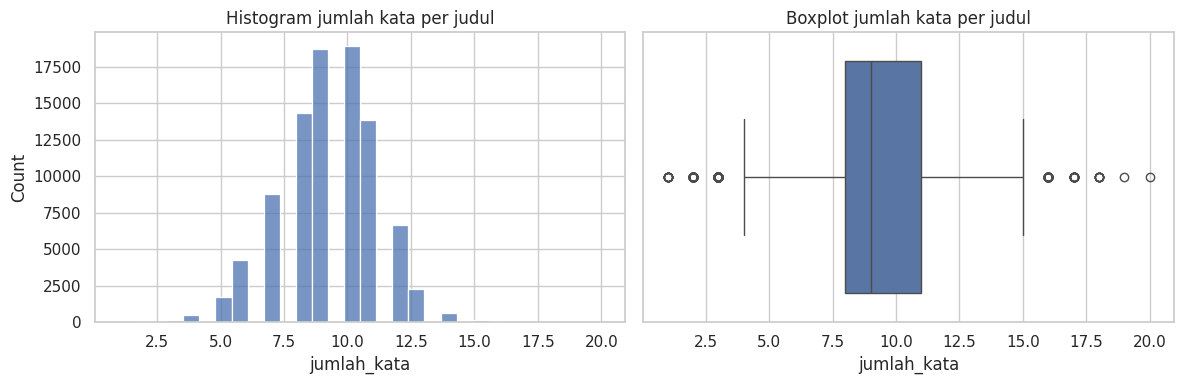

count    91017.000000
mean         9.275751
std          1.890514
min          1.000000
25%          8.000000
50%          9.000000
75%         11.000000
max         20.000000
Name: jumlah_kata, dtype: float64


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["jumlah_kata"], bins=30, ax=ax[0]); ax[0].set_title("Histogram jumlah kata per judul")
sns.boxplot(x=df["jumlah_kata"], ax=ax[1]);         ax[1].set_title("Boxplot jumlah kata per judul")
plt.tight_layout(); plt.show()
print(df["jumlah_kata"].describe())

**Temuan:** Median jumlah kata per judul adalah 9 (IQR 8–11, maksimum 20). Hanya 89 judul (0,1%) melebihi batas atas IQR (16 kata).
**Bukti:** `describe()` pada output di atas dan perhitungan outlier pada bagian 6.
**Interpretasi:** Distribusi hampir simetris (skewness −0,14) dan outlier sangat sedikit. Judul terpanjang berasal dari kategori `food`, banyak di antaranya dari rubrik berjudul tetap ("Sahur dan Buka di Rumah Aja ..."), jadi panjangnya wajar dan bukan kesalahan data.
**Implikasi:** Judul panjang tidak perlu dibuang atau ditransformasi.

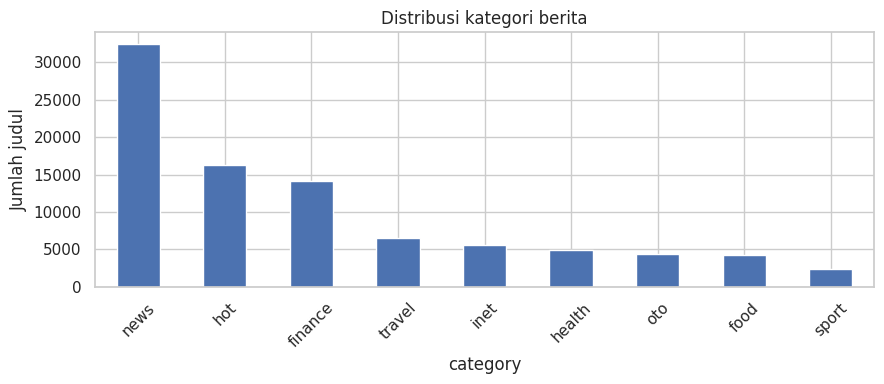

category
news       0.356
hot        0.179
finance    0.156
travel     0.071
inet       0.062
health     0.054
oto        0.048
food       0.047
sport      0.027
Name: count, dtype: float64


In [ ]:
plt.figure(figsize=(9, 4))
vc.plot(kind="bar")
plt.title("Distribusi kategori berita"); plt.ylabel("Jumlah judul"); plt.xticks(rotation=45)
plt.tight_layout(); plt.show()
print((vc / len(df)).round(3))

**Temuan:** Jumlah judul per kategori jauh tidak seimbang: `news` (32.360 judul, 35,6%) dibanding `sport` (2.436 judul, 2,7%), rasio 13,3 : 1.
**Bukti:** nilai `value_counts` dan proporsi pada output di atas.
**Interpretasi:** model cenderung condong ke kategori mayoritas, dan akurasi saja akan menyesatkan (menebak `news` terus sudah memberi akurasi 35,6%).
**Implikasi:** memakai stratified split dan macro-F1 sebagai metrik utama. Pemakaian `class_weight` tidak diasumsikan baik, tetapi dibandingkan dengan tanpa weight (Bagian 3 dan 5.3).

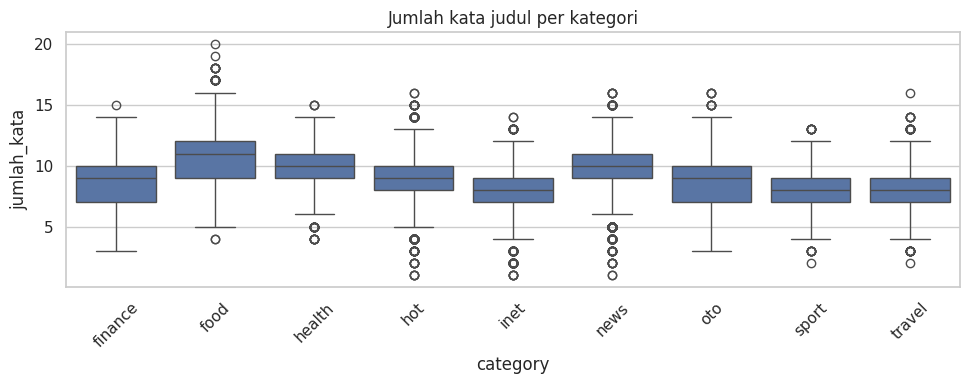

In [ ]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x=LABEL_COL, y="jumlah_kata")
plt.title("Jumlah kata judul per kategori"); plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

In [ ]:
print(df.groupby(LABEL_COL)["jumlah_kata"].agg(["median", "mean", "std"]).round(2).to_string())

          median   mean   std
category                     
finance      9.0   8.49  1.63
food        11.0  10.71  2.01
health      10.0   9.73  1.57
hot          9.0   9.10  1.79
inet         8.0   8.02  1.77
news        10.0  10.04  1.62
oto          9.0   8.79  1.97
sport        8.0   8.16  1.73
travel       8.0   8.13  1.72


**Temuan:** Panjang judul berbeda antar kategori: median `food` 11 kata, `health` dan `news` 10, sedangkan `inet`, `sport`, dan `travel` 8.
**Bukti:** tabel median/mean/std per kategori dan boxplot di atas (std di dalam kategori 1,6–2,0 kata).
**Interpretasi:** Selisih sekitar 3 kata antar kategori ekstrem setara dengan kira-kira 1,5–2 kali std di dalam kategori, jadi ada sinyal tetapi tumpang tindih besar. Panjang judul hanya pembeda lemah.
**Implikasi:** `jumlah_kata` layak diuji sebagai fitur tambahan (Bagian 3, D2), tetapi tidak diharapkan menjadi fitur utama.

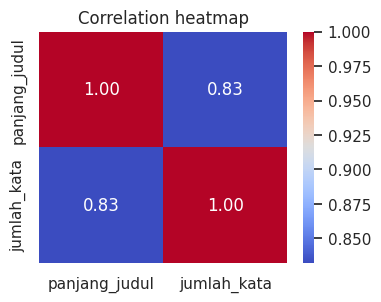

               panjang_judul  jumlah_kata
panjang_judul           1.00         0.83
jumlah_kata             0.83         1.00


In [ ]:
plt.figure(figsize=(4, 3))
sns.heatmap(df[["panjang_judul", "jumlah_kata"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap"); plt.show()
print(df[["panjang_judul", "jumlah_kata"]].corr().round(2).to_string())

**Temuan:** `panjang_judul` dan `jumlah_kata` berkorelasi tinggi (r = 0,83).
**Bukti:** nilai pada heatmap dan tabel korelasi di atas.
**Interpretasi:** Judul dengan lebih banyak kata cenderung lebih panjang karakter, tetapi korelasinya tidak mendekati 1 karena panjang kata juga bervariasi. Keduanya redundan sebagian, bukan identik.
**Implikasi:** Agar tidak menambah fitur ganda, eksperimen fitur tambahan hanya memakai `jumlah_kata` yang lebih mudah ditafsirkan.

### EDA tambahan: kata paling khas per kategori

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

# EDA deskriptif (tidak dipakai untuk melatih model): kata dengan "lift" tertinggi per kategori,
# yaitu kata yang jauh lebih sering muncul pada satu kategori dibanding seluruh data.
cv_eda = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b", min_df=50)
M = (cv_eda.fit_transform(df[TEXT_COL]) > 0).astype(int)
vocab_eda = np.array(cv_eda.get_feature_names_out())
p_all = np.asarray(M.sum(0)).ravel() / len(df)
for kat in sorted(df[LABEL_COL].unique()):
    idx = np.where(df[LABEL_COL].values == kat)[0]
    n_kat = np.asarray(M[idx].sum(0)).ravel()
    lift = (n_kat / len(idx)) / p_all
    kandidat = np.where(n_kat >= 30)[0]          # minimal muncul di 30 judul pada kategori tsb
    top = kandidat[np.argsort(lift[kandidat])[::-1][:8]]
    print(f"{kat:8s}: {', '.join(vocab_eda[top])}")

finance : diproyeksi, spt, inflasi, ihsg, bahlil, antam, menguat, erick
food    : gurih, galeri, kulineran, resto, resep, kue, enak, pizza
health  : bercinta, infeksi, studi, kenali, who, seks, paru, gejala
hot     : utami, vicky, chris, chord, entertainment, sinopsis, manggung, isyana
inet    : realme, oppo, huawei, samsung, vivo, xiaomi, galaxy, android
news    : zuraida, gubsu, gowa, kkb, pemko, sidrap, jakpus, nasdem
oto     : toyota, otomotif, nmax, suv, suzuki, nissan, honda, tesla
sport   : khabib, pbsi, masters, england, gol, tontowi, bulutangkis, mcgregor
travel  : candi, traveler, destinasi, borobudur, traveling, wisata, wisatawan, turis


**Temuan:** Kata khas (lift tertinggi) membentuk pola jelas pada sebagian besar kategori: `inet` (merek ponsel: realme, oppo, huawei, samsung), `oto` (toyota, suzuki, honda, nissan), `sport` (khabib, pbsi, bulutangkis, mcgregor), `travel` (candi, borobudur, wisata, destinasi), `food` (resep, kue, pizza, resto), dan `finance` (inflasi, ihsg, spt). Sebaliknya `news` bercirikan nama daerah dan partai (gubsu, gowa, pks, nasdem, pemko), dan `hot` nama figur hiburan (chris, vicky, utami, mutia).
**Bukti:** daftar kata pada output di atas.
**Interpretasi:** Pembeda utama kategori adalah kosakata topik dan nama diri (merek, tokoh, tempat). `news` tidak memiliki satu tema tunggal, sehingga diduga menjadi kategori yang paling sulit dipisahkan dari kategori lain (diperiksa pada analisis kesalahan).
**Implikasi:** Representasi TF-IDF kata/bigram sesuai untuk masalah ini. Karena banyak nama diri yang jarang muncul, batas 5.000 fitur berpotensi membuang informasi (diuji pada ablation kosakata, Bagian 3 D).

## 6. Data Quality Findings

In [ ]:
print("Missing value per kolom:"); display(df.isna().sum()[df.isna().sum() > 0])
print("\nBaris duplikat penuh:", df.duplicated().sum())
print("Judul duplikat:", df[TEXT_COL].duplicated().sum())
print("Skewness jumlah_kata:", round(df["jumlah_kata"].skew(), 2))

q1, q3 = df["jumlah_kata"].quantile([0.25, 0.75]); iqr = q3 - q1
batas_atas = q3 + 1.5 * iqr
n_out = (df["jumlah_kata"] > batas_atas).sum()
print(f"Outlier jumlah_kata (IQR): {n_out} baris ({n_out/len(df):.1%}), batas atas = {batas_atas:.0f} kata")

rasio = vc.max() / vc.min()
print(f"Rasio kategori terbesar ({vc.index[0]}) : terkecil ({vc.index[-1]}) = {rasio:.1f} : 1")

Missing value per kolom:


,0



Baris duplikat penuh: 8
Judul duplikat: 126
Skewness jumlah_kata: -0.14
Outlier jumlah_kata (IQR): 89 baris (0.1%), batas atas = 16 kata
Rasio kategori terbesar (news) : terkecil (sport) = 13.3 : 1


In [ ]:
# (a) Apakah kolom url membocorkan label?
df["url_host"] = df["url"].str.extract(r"https?://([^.]+)\.detik\.com")[0]
ada_url = df["url_host"].notna()
print("Baris dengan url valid          :", ada_url.sum())
print("Baris dengan url '#'            :", (~ada_url).sum(), "-> kategori:", df.loc[~ada_url, LABEL_COL].unique().tolist())
print("Subdomain url == category       :", f"{(df.loc[ada_url, 'url_host'] == df.loc[ada_url, LABEL_COL]).mean():.1%} (dari url valid)")

# (b) Judul duplikat dengan label berbeda
dup = df[df[TEXT_COL].duplicated(keep=False)]
label_per_judul = dup.groupby(TEXT_COL)[LABEL_COL].nunique()
print("\nJudul unik yang muncul >1 kali  :", len(label_per_judul))
print("   di antaranya berlabel konflik :", int((label_per_judul > 1).sum()))

# (c) Judul terpanjang (kandidat outlier)
print("\n5 judul terpanjang:")
print(df.sort_values("jumlah_kata", ascending=False)[[TEXT_COL, "jumlah_kata", LABEL_COL]].head(5).to_string(index=False))

Baris dengan url valid          : 85377
Baris dengan url '#'            : 5640 -> kategori: ['inet']
Subdomain url == category       : 100.0% (dari url valid)

Judul unik yang muncul >1 kali  : 109
   di antaranya berlabel konflik : 29

5 judul terpanjang:
                                                                                                  title  jumlah_kata category
 Sahur dan Buka di Rumah Aja Malas Masak? Menu Sahur dan Buka Bisa Dipesan dari Tempat Makan 24 Jam Ini           20     food
Sahur dan Buka di Rumah Aja Menu Harian Ramadhan ke-12 : Hidangan Serba Tahu Untuk Sahur dan Buka Puasa           19     food
            Sahur dan Buka di Rumah Aja 5 Tempat Beli Bakcang Halal Isi Ayam dan Telur Asin yang Mantul           18     food
                   Sahur dan Buka di Rumah Aja Cuma Rp 20 Ribuan, Boba untuk Buka Puasa di 5 Tempat ini           18     food
         Makan Enak di Era Baru Makan di Mobil Lagi Hits, Ini Tips Aman dan Nyaman Kalau Mau Mencobanya          

| No | Temuan | Bukti | Implikasi |
|---|---|---|---|
| 1 | Kategori tidak seimbang | `news` 32.360 judul vs `sport` 2.436 judul (rasio 13,3 : 1) | stratified split, macro-F1 sebagai metrik utama, `class_weight` dibandingkan dengan tanpa weight |
| 2 | Judul duplikat | 126 baris kelebihan (8 baris duplikat penuh); 109 judul unik muncul lebih dari sekali, 29 di antaranya berlabel berbeda | hapus duplikat sebelum split agar tidak bocor antara latih dan uji; label konflik perlu diaudit (rencana UAS) |
| 3 | Kolom `url` membocorkan label | subdomain url = `category` pada 100% url valid (85.377 baris); 5.640 url bernilai `#` dan semuanya `inet` | `url` tidak dipakai sebagai fitur |
| 4 | Outlier panjang judul sangat sedikit | skewness −0,14; 89 judul (0,1%) lebih dari 16 kata | tidak perlu transformasi atau pembuangan |
| 5 | Pergeseran waktu dan dominasi COVID | data 1 Jan – 13 Jun 2020; pangsa judul COVID 2,4% (Jan) → 39,9% (Mar) | split temporal direncanakan sebagai pembanding |
| 6 | Missing value | 0 pada semua kolom | tidak perlu imputasi |

## 7. Preprocessing Plan
| Masalah | Variabel | Rencana Penanganan | Alasan |
|---|---|---|---|
| Kategori tidak seimbang | category | Stratified train-test split (dijalankan); `class_weight="balanced"` dibandingkan dengan tanpa weight | Menjaga proporsi kelas; efek class_weight diuji, bukan diasumsikan |
| Data duplikat | title | `drop_duplicates` berdasarkan judul sebelum split (dijalankan, 126 baris dibuang) | Menghindari judul sama di train dan test |
| Kebocoran lewat url | url | Kolom tidak dipakai sebagai fitur | Subdomain url identik dengan label |
| Outlier panjang judul | jumlah_kata | Tidak ditransformasi atau dibuang | Skewness −0,14 dan hanya 0,1% outlier |
| Target kategorikal | category | Label dikodekan otomatis oleh estimator scikit-learn | Estimator membutuhkan target diskret |
| Data teks | title | Lowercase, hapus URL/simbol, TF-IDF unigram+bigram; TF-IDF di-fit hanya pada data latih (di dalam `Pipeline` pada CV) | Representasi teks menjadi vektor numerik tanpa kebocoran |
| Skala fitur numerik | jumlah_kata, ada_angka, rasio_kata_unik | `StandardScaler` di dalam `ColumnTransformer` (dipakai pada uji fitur, Bagian 3 D2) | Menyamakan skala sebelum digabung dengan TF-IDF |
| Tanggal | date | Dipakai untuk EDA; belum untuk split | Split temporal direncanakan pasca-UTS |

## 8. Initial Feature Engineering
| Kandidat Fitur | Dibentuk dari | Hipotesis | Hasil pemeriksaan |
|---|---|---|---|
| jumlah_kata | jumlah kata pada judul | Panjang judul berbeda antar kategori (EDA: median 8 sampai 11 kata) | Diuji pada Bagian 3 D2 |
| ada_angka | judul mengandung digit atau tidak | Kategori tertentu lebih sering memuat angka | Hipotesis awal (finance dan sport) tidak didukung data, lihat di bawah; diuji pada Bagian 3 D2 |
| rasio_kata_unik | kata unik / total kata dalam judul | Judul dengan kata berulang berasosiasi dengan kategori tertentu | Hampir konstan, lihat di bawah; diuji pada Bagian 3 D2 |

In [ ]:
df["rasio_kata_unik"] = df[TEXT_COL].apply(lambda s: len(set(s.lower().split())) / max(len(s.split()), 1))
df["ada_angka"]       = df[TEXT_COL].str.contains(r"\d").astype(int)
df[["rasio_kata_unik", "ada_angka"]].describe().T

,count,mean,std,min,25%,50%,75%,max
rasio_kata_unik,91017.0,0.996213,0.020069,0.666667,1.0,1.0,1.0,1.0
ada_angka,91017.0,0.276069,0.447054,0.000000,0.0,0.0,1.0,1.0


In [ ]:
print(df.groupby(LABEL_COL)[["ada_angka", "rasio_kata_unik"]].mean().round(3).to_string())
print("\nRata-rata ada_angka keseluruhan:", round(df["ada_angka"].mean(), 3))
print("Judul dengan rasio_kata_unik < 1:", f"{(df['rasio_kata_unik'] < 1).mean():.1%}")

          ada_angka  rasio_kata_unik
category                            
finance       0.293            0.998
food          0.363            0.986
health        0.364            0.997
hot           0.155            0.998
inet          0.318            0.997
news          0.321            0.996
oto           0.268            0.996
sport         0.269            0.998
travel        0.164            0.996

Rata-rata ada_angka keseluruhan: 0.276
Judul dengan rasio_kata_unik < 1: 3.8%


**Hasil pemeriksaan hipotesis:** Dugaan awal bahwa `finance` dan `sport` paling sering memuat angka **tidak didukung** data: proporsinya 0,293 dan 0,269, dekat dengan rata-rata keseluruhan 0,276. Proporsi tertinggi justru `health` (0,364) dan `food` (0,363), terendah `hot` (0,155) dan `travel` (0,164). `rasio_kata_unik` nyaris konstan: sekitar 96% judul bernilai 1 (tidak ada kata berulang), sehingga daya pembedanya diperkirakan sangat rendah. Dampak ketiga fitur terhadap model diukur pada Bagian 3 D2.

## 9. Initial Data Pipeline (ringkasan)
Pipeline yang dijalankan pada Bagian 2 dan Bagian 3:
1. Muat data dari URL → hapus duplikat judul dan baris tanpa label/judul kosong.
2. Bersihkan teks (lowercase, hapus URL dan simbol).
3. Split stratified 80:20 (`random_state=42`) menjadi data latih dan data uji.
4. TF-IDF unigram+bigram di-fit **hanya pada data latih** (pada CV, di dalam `Pipeline` sehingga di-fit ulang per fold).
5. Latih model → evaluasi dengan CV pada data latih dan satu kali pada data uji.

Kode pipeline yang sebenarnya ada pada Bagian 2 (C, D) dan Bagian 3 (fungsi `buat_pipe`).

## 10. Kesimpulan Task 02 (Standar Hasil Tahap 2)
1. **Masalah:** Memprediksi kategori berita dari judulnya.
2. **Data:** Indonesian News Title Dataset dari detik.com (91.017 judul, 9 kategori, 1 Jan – 13 Jun 2020).
3. **Temuan:** Kategori tidak seimbang (13,3 : 1), ada judul duplikat (29 di antaranya berlabel konflik), kolom `url` membocorkan label, dan panjang judul hampir simetris dengan outlier sangat sedikit.
4. **Persiapan:** Hapus duplikat, stratified split, `url` tidak dipakai, TF-IDF di-fit hanya pada data latih.
5. **Fitur:** TF-IDF dari judul yang sudah dibersihkan sebagai fitur utama. Fitur turunan (`jumlah_kata`, `ada_angka`, `rasio_kata_unik`) diuji dampaknya pada Bagian 3 D2.

---

# BAGIAN 2 — PERTEMUAN 3: BASELINE MODEL & EVALUASI AWAL (TEXT MINING) (Bagian Matthew Rivandy)

## A. Problem
**Rumusan masalah:** Bagaimana memprediksi kategori sebuah berita hanya dari judulnya?
**Tujuan:** Membangun model baseline sederhana sebagai pembanding awal, untuk mengetahui seberapa baik masalah ini bisa diselesaikan sebelum masuk ke pengembangan model lebih lanjut.
**Target:** kolom `category` (9 kelas).
**Fitur:** representasi TF-IDF dari judul berita yang sudah dibersihkan.
**Jenis masalah:** Text Classification / Text Mining (klasifikasi teks multi-kelas).

## B. Dataset
Sama seperti Bagian 1: Indonesian News Title Dataset, 91.017 baris, fitur `title`, target `category`, kualitas data: ada duplikat dan ketidakseimbangan kelas (sudah ditangani pada preprocessing di bawah).

## C. Preprocessing

**Langkah dan alasannya:**
1. Hapus data duplikat (berdasarkan judul) — mencegah judul yang sama muncul di data latih dan uji (data leakage).
2. Hapus baris dengan label kosong atau judul kosong — baris tanpa target atau teks tidak bisa dipakai.
3. Case folding (lowercase) — menyamakan variasi huruf besar/kecil.
4. Hapus URL dan karakter non-alfanumerik — karakter tersebut tidak membawa informasi kategori.
5. Kolom `url` dan `date` tidak dipakai sebagai fitur — `url` membocorkan label (subdomain = kategori).
6. Train-test split 80:20 dengan stratifikasi pada label.
7. TF-IDF vectorization (unigram + bigram, maksimal 5000 fitur) di-fit hanya pada data latih.

In [ ]:
def bersihkan(s):
    s = s.lower()
    s = re.sub(r"http\S+|www\.\S+", " ", s)
    s = re.sub(r"[^a-z0-9\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

data = df.drop_duplicates(subset=[TEXT_COL]).dropna(subset=[LABEL_COL]).copy()
data = data[data[TEXT_COL].str.strip() != ""]
data["teks_bersih"] = data[TEXT_COL].apply(bersihkan)

print("Jumlah baris sebelum preprocessing :", df.shape[0])
print("Jumlah baris setelah preprocessing  :", data.shape[0])
print(f"Baris yang dibuang (duplikat/kosong): {df.shape[0] - data.shape[0]}")
display(data[[TEXT_COL, "teks_bersih", LABEL_COL]].sample(5, random_state=42))

Jumlah baris sebelum preprocessing : 91017
Jumlah baris setelah preprocessing  : 90891
Baris yang dibuang (duplikat/kosong): 126


,title,teks_bersih,category
31770,Mama Amy Bicara Kondisi Nagita Slavina Usai Ke...,mama amy bicara kondisi nagita slavina usai ke...,hot
65597,"Yatim Piatu, 3 Anak Difabel Positif Corona di ...",yatim piatu 3 anak difabel positif corona di j...,news
42315,Berbagi Tips Kebugaran ala Seleb TikTok,berbagi tips kebugaran ala seleb tiktok,inet
14739,5 Makanan Penekan Nafsu Makan Alami yang Rasan...,5 makanan penekan nafsu makan alami yang rasan...,food
90751,PR Besar! Jumlah Turis Asing Turun di Desember...,pr besar jumlah turis asing turun di desember ...,travel


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = data["teks_bersih"]
y = data[LABEL_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec  = tfidf.transform(X_test)

print("Bentuk data latih (TF-IDF):", X_train_vec.shape)
print("Bentuk data uji   (TF-IDF):", X_test_vec.shape)

Bentuk data latih (TF-IDF): (72712, 5000)
Bentuk data uji   (TF-IDF): (18179, 5000)


## D. Baseline
**Algoritma baseline:** TF-IDF + Logistic Regression, sesuai pedoman project untuk kasus Text Classification.
`class_weight="balanced"` dipakai supaya model tidak terlalu bias ke kategori mayoritas (`news`).

In [ ]:
from sklearn.linear_model import LogisticRegression

t0 = time.time()
baseline = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
baseline.fit(X_train_vec, y_train)
print(f"Waktu training: {time.time() - t0:.1f} detik")

Waktu training: 24.6 detik


In [ ]:
y_pred = baseline.predict(X_test_vec)

contoh = X_test.sample(8, random_state=1)
hasil_contoh = pd.DataFrame({
    "judul_asli": data.loc[contoh.index, TEXT_COL].values,
    "label_sebenarnya": y_test.loc[contoh.index].values,
    "prediksi": baseline.predict(tfidf.transform(contoh)),
})
hasil_contoh

,judul_asli,label_sebenarnya,prediksi
0,Kasus Positif Corona di RI Bertambah Jadi 1.28...,news,news
1,Doa Nabila ke Netizen yang Ramal Dirinya dan M...,hot,hot
2,"Tampil Ganteng Mirip Kakaknya, Kawasaki Z125 D...",oto,oto
3,Polisi Sebut Peserta The Voice Indonesia 2019 ...,news,news
4,Yusuf Mansur Lihat Hikmah dari Kebangkitan Did...,hot,hot
5,BNI Digitalkan BNI Java Jazz 2020,finance,hot
6,"Temui Massa, Anggota Komisi IX Setuju Omnibus ...",news,news
7,Gaji Bos Gojek Dipotong buat Driver Terdampak ...,finance,finance


## E. Desain Evaluasi dan Evaluasi Awal

**Pembagian data dan validasi:**
- Hold-out stratified 80:20 (72.712 data latih, 18.179 data uji, `random_state=42`).
- Pemilihan model memakai 5-fold stratified CV **pada data latih** (Bagian 3). Data uji dipakai untuk melaporkan hasil, bukan memilih model.

**Metrik:** macro-F1 sebagai metrik utama (kelas tidak seimbang 13,3 : 1 dan setiap kategori dianggap setara), accuracy sebagai pendamping, macro precision/recall, F1 per kelas, dan confusion matrix.

**Pencegahan data leakage:**
1. Judul duplikat dihapus sebelum split.
2. TF-IDF di-fit hanya pada data latih; pada CV dimasukkan ke dalam `Pipeline` sehingga di-fit ulang pada tiap fold.
3. Kolom `url` tidak dipakai karena subdomainnya identik dengan label.
4. Fitur numerik dihitung per baris, dan `StandardScaler` berada di dalam pipeline.
5. Semua model dibandingkan dengan fold yang sama.

**Risiko yang masih ada:** (a) pembagian acak pada data berurutan waktu bisa lebih optimistis daripada pembagian temporal; (b) judul yang mirip tetapi tidak identik (near-duplicate) belum dideteksi; (c) 29 judul berlabel konflik dibuang dengan aturan "ambil yang pertama".

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, classification_report, confusion_matrix)

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="macro")
rec  = recall_score(y_test, y_pred, average="macro")
f1   = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy          : {acc:.3f}")
print(f"Precision (macro) : {prec:.3f}")
print(f"Recall (macro)    : {rec:.3f}")
print(f"F1-score (macro)  : {f1:.3f}")
print()
print(classification_report(y_test, y_pred))

Accuracy          : 0.796
Precision (macro) : 0.733
Recall (macro)    : 0.797
F1-score (macro)  : 0.760

              precision    recall  f1-score   support

     finance       0.79      0.80      0.80      2828
        food       0.77      0.85      0.81       863
      health       0.56      0.80      0.66       983
         hot       0.87      0.83      0.85      3260
        inet       0.68      0.76      0.72      1126
        news       0.93      0.78      0.85      6466
         oto       0.68      0.81      0.74       875
       sport       0.66      0.77      0.72       487
      travel       0.65      0.77      0.70      1291

    accuracy                           0.80     18179
   macro avg       0.73      0.80      0.76     18179
weighted avg       0.81      0.80      0.80     18179



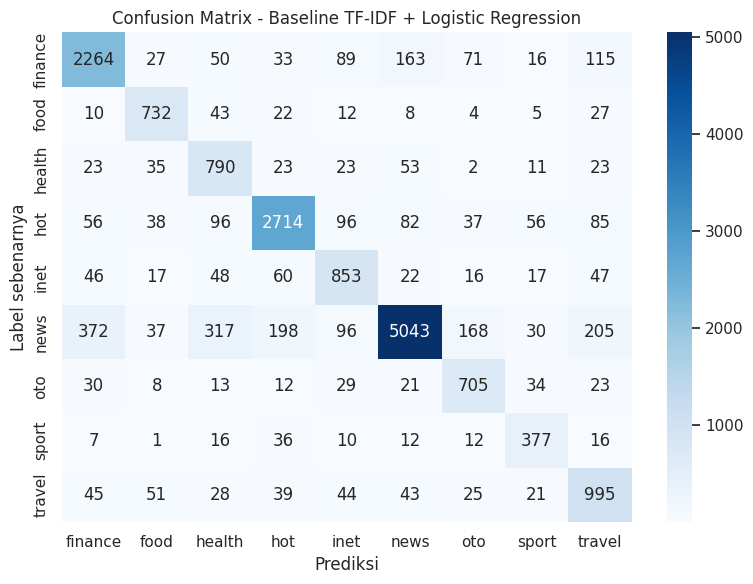

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=baseline.classes_)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=baseline.classes_, yticklabels=baseline.classes_)
plt.xlabel("Prediksi"); plt.ylabel("Label sebenarnya")
plt.title("Confusion Matrix - Baseline TF-IDF + Logistic Regression")
plt.tight_layout(); plt.show()

In [ ]:
# Pasangan kesalahan terbanyak pada baseline (aktual -> prediksi)
cl = baseline.classes_
pairs = [(cl[i], cl[j], cm[i, j]) for i in range(len(cl)) for j in range(len(cl)) if i != j]
print(pd.DataFrame(pairs, columns=["Aktual", "Prediksi", "Jumlah"]).sort_values("Jumlah", ascending=False).head(6).to_string(index=False))

 Aktual Prediksi  Jumlah
   news  finance     372
   news   health     317
   news   travel     205
   news      hot     198
   news      oto     168
finance     news     163


**Interpretasi singkat:**
Baseline mencapai accuracy 0,796 dan macro-F1 0,760 (macro precision 0,733; macro recall 0,797). Macro-F1 lebih rendah dari accuracy karena precision kelas-kelas kecil rendah: `health` 0,56, `travel` 0,65, `sport` 0,66, serta `inet` dan `oto` 0,68, padahal recall kelas-kelas itu 0,76–0,81. Sebaliknya `news` memiliki precision 0,93 tetapi recall hanya 0,78. Pola ini sejalan dengan `class_weight="balanced"`: model lebih berani memprediksi kelas kecil, sehingga banyak judul `news` salah diprediksi sebagai `finance`, `health`, `travel`, `hot`, atau `oto` (pasangan kesalahan terbanyak pada tabel di atas).

**Apa arti hasil baseline ini terhadap masalah yang kami pilih?**
Dari judul saja, model sederhana sudah menebak kategori dengan benar pada sekitar 80% judul uji, sehingga masalah ini layak diselesaikan dengan classical machine learning. Namun kinerjanya belum merata, dan sebagian kesalahan kemungkinan berasal dari pilihan `class_weight` pada baseline itu sendiri. Karena itu perbandingan dengan tanpa `class_weight`, kosakata yang lebih besar, dan algoritma lain diperlukan (Bagian 3).

## F. Temuan Awal
- **Apa yang berhasil?** Baseline TF-IDF + Logistic Regression berhasil dilatih dan memprediksi kategori dengan accuracy 0,796 dan macro-F1 0,760 pada data uji.
- **Apa masalah yang ditemukan?** Precision rendah pada `health` (0,56), `travel` (0,65), dan `sport` (0,66) walaupun recall-nya tinggi, sementara recall `news` hanya 0,78. `health` bukan kelas terkecil (4.919 judul, peringkat 6 dari 9), jadi rendahnya precision tidak semata karena jumlah data.
- **Apa kelemahan baseline?** Hanya memakai judul, TF-IDF dibatasi 5000 fitur, belum ada fitur tambahan, belum ada tuning, dan `class_weight="balanced"` belum dibandingkan dengan tanpa weight.
- **Apa yang perlu diperbaiki pada tahap berikutnya?** Membandingkan kandidat model (Naive Bayes, LinearSVC, SGD) dengan fold yang sama, menguji ukuran kosakata, menguji pengaruh `class_weight`, dan mengukur dampak fitur tambahan. Hasilnya ada di Bagian 3.

---

# BAGIAN 3 — PERTEMUAN 4: KANDIDAT MODEL TAMBAHAN & PERBANDINGAN DENGAN BASELINE (Bagian Oktapianus Zalukhu)

**Aturan yang dipegang:**
1. **Perbandingan yang adil:** semua model memakai split, representasi fitur (TF-IDF 5000 fitur, unigram+bigram), dan metrik yang sama dengan baseline.
2. **Seleksi hanya dari cross-validation (CV) pada data latih.** Data uji hanya melaporkan hasil, tidak dipakai untuk memilih model.
3. TF-IDF berada **di dalam `Pipeline`**, sehingga di-fit hanya pada data latih tiap fold (mencegah data leakage).
4. Semua interpretasi ditulis dari output yang muncul pada notebook ini.

In [ ]:
import pandas as pd
import numpy as np
import warnings
import re

from sklearn.model_selection import train_test_split
from IPython.display import display

warnings.filterwarnings("ignore")

SEED = 42
TEXT_COL = "title"
LABEL_COL = "category"

if all(v in globals() for v in ("X_train", "X_test", "y_train", "y_test")):

    print("Memakai variabel dari Bagian 2:")
    print("X_train, X_test, y_train, y_test")

else:
    print("Variabel Bagian 2 tidak ditemukan.")
    print("Menyiapkan data menggunakan langkah yang sama seperti Bagian 2.")

    URL = "https://raw.githubusercontent.com/ibamibrahim/dataset-judul-berita-indonesia/master/detik_news_title.csv"

    df = pd.read_csv(URL)

    df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)

    def bersihkan(s):
        s = s.lower()
        s = re.sub(r"http\S+|www\.\S+", " ", s)
        s = re.sub(r"[^a-z0-9\s]", " ", s)
        return re.sub(r"\s+", " ", s).strip()

    data = df.drop_duplicates(subset=[TEXT_COL]).dropna(
        subset=[LABEL_COL]
    ).copy()

    data = data[data[TEXT_COL].str.strip() != ""]

    data["teks_bersih"] = data[TEXT_COL].apply(bersihkan)

    X_train, X_test, y_train, y_test = train_test_split(
        data["teks_bersih"],
        data[LABEL_COL],
        test_size=0.2,
        random_state=SEED,
        stratify=data[LABEL_COL]
    )

print("\n===== INFORMASI DATA =====")
print("Data latih :", len(X_train))
print("Data uji   :", len(X_test))
print("Jumlah kelas:", y_train.nunique())
print("Distribusi kelas training:")
display(y_train.value_counts())


Memakai variabel dari Bagian 2:
X_train, X_test, y_train, y_test

===== INFORMASI DATA =====
Data latih : 72712
Data uji   : 18179
Jumlah kelas: 9
Distribusi kelas training:


,count
category,
news,25864
hot,13040
finance,11313
travel,5163
inet,4503
health,3931
oto,3500
food,3451
sport,1947


## A. Rencana kandidat model dan alasan pemilihannya
Baseline Anda: **TF-IDF + Logistic Regression** (`class_weight="balanced"`). Kandidat tambahan dipilih karena cocok untuk data teks TF-IDF yang jarang (*sparse*) dan berdimensi tinggi:

| Kandidat | Alasan dipilih |
|---|---|
| Dummy (majority) | Batas bawah mutlak: seberapa jauh model 'tanpa belajar' bisa mencapai metrik |
| MultinomialNB, ComplementNB | Model probabilistik klasik untuk teks; sangat cepat; ComplementNB dirancang untuk kelas tidak seimbang |
| LinearSVC | Pemisah linear margin maksimum; umumnya sangat kuat pada TF-IDF |
| LinearSVC (`class_weight="balanced"`) | Menguji apakah pembobotan kelas membantu pada model ini |
| SGDClassifier (`modified_huber`) | Model linear yang dilatih dengan SGD; murah dan skalabel, pembanding keluarga linear lain |

Perbandingan antar keluarga model probabilistik, margin-based, dan SGD bermanfaat karena setiap model memiliki cara kerja yang berbeda dalam mempelajari pola dan mengklasifikasikan teks berita. Model probabilistik seperti Naive Bayes menghitung peluang suatu kata terhadap kategori berita, sedangkan model margin-based seperti SVM berusaha mencari batas pemisah terbaik antar kelas. Sementara itu, SGD menggunakan proses optimasi bertahap untuk mempelajari pola dari data.

Dengan membandingkan ketiga keluarga model tersebut, kita dapat mengetahui metode mana yang paling efektif dalam mengklasifikasikan judul berita berdasarkan kategori. Selain itu, perbandingan ini membantu mengetahui apakah model alternatif mampu menghasilkan nilai Macro-F1 yang lebih baik dibandingkan model baseline.

Hipotesis saya adalah LinearSVC berpotensi mengalahkan baseline Logistic Regression karena LinearSVC mampu mencari batas pemisah yang optimal pada data teks berdimensi tinggi yang direpresentasikan menggunakan TF-IDF unigram dan bigram. Dengan demikian, LinearSVC diperkirakan dapat mengenali pola kata dan hubungan antar kata dalam judul berita dengan lebih baik sehingga menghasilkan nilai Macro-F1 yang lebih tinggi.

In [ ]:

import time

from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix

NAMA_BASELINE = "BASELINE: LogReg balanced"

def buat_pipe(clf, max_features=5000):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=max_features,
            ngram_range=(1, 2)
        )),
        ("clf", clf)
    ])

KANDIDAT = {
    "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
    NAMA_BASELINE: LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "ComplementNB (alpha=0.3)": ComplementNB(alpha=0.3),
    "MultinomialNB (alpha=0.1)": MultinomialNB(alpha=0.1),
    "LinearSVC (C=0.1)": LinearSVC(C=0.1, max_iter=5000, random_state=SEED),
    "LinearSVC (C=0.3)": LinearSVC(C=0.3, max_iter=5000, random_state=SEED),
    "LinearSVC (C=1.0)": LinearSVC(C=1.0, max_iter=5000, random_state=SEED),
    "LinearSVC balanced (C=0.3)": LinearSVC(C=0.3, class_weight="balanced", max_iter=5000, random_state=SEED),
    "SGD modified_huber": SGDClassifier(loss="modified_huber", alpha=1e-5, max_iter=50, random_state=SEED),
}

print(len(KANDIDAT), "model dibandingkan:", list(KANDIDAT))


9 model dibandingkan: ['Dummy (majority)', 'BASELINE: LogReg balanced', 'ComplementNB (alpha=0.3)', 'MultinomialNB (alpha=0.1)', 'LinearSVC (C=0.1)', 'LinearSVC (C=0.3)', 'LinearSVC (C=1.0)', 'LinearSVC balanced (C=0.3)', 'SGD modified_huber']


## B. Desain perbandingan
- **Validasi:** 5-fold stratified CV pada data latih (shuffle, seed 42). **Fold yang sama** dipakai untuk semua model sehingga skor per fold dapat dibandingkan berpasangan.
- **Metrik utama:** macro-F1 (kelas tidak seimbang; semua kelas setara). Pendamping: akurasi.
- **Pembanding:** selisih macro-F1 terhadap baseline (Δ), dan di berapa dari 5 fold model mengalahkan baseline.

Fold yang sama harus digunakan untuk semua model agar perbandingan dilakukan secara adil dan konsisten. Dengan menggunakan pembagian data training dan validasi yang sama pada setiap fold, setiap model diuji menggunakan data yang sama sehingga perbedaan hasil evaluasi lebih mencerminkan kemampuan model, bukan karena perbedaan pembagian data. Selain itu, penggunaan StratifiedKFold membantu menjaga proporsi setiap kategori berita agar tetap seimbang pada setiap fold.

Macro-F1 digunakan sebagai metrik utama karena dataset berita dapat memiliki jumlah data yang berbeda pada setiap kategori. Akurasi saja belum cukup untuk menilai kemampuan model, karena model bisa mendapatkan akurasi tinggi tetapi kurang baik dalam mengenali kategori yang jumlah datanya sedikit. Macro-F1 menghitung nilai F1 setiap kelas secara terpisah, kemudian mengambil rata-ratanya dengan bobot yang sama. Dengan demikian, setiap kategori berita mendapatkan perhatian yang sama dalam evaluasi.

Oleh karena itu, kandidat model dianggap lebih baik dari baseline apabila menghasilkan nilai Macro-F1 yang lebih tinggi secara konsisten pada fold yang sama, bukan hanya memiliki akurasi yang tinggi.

## C. Cross-validation semua kandidat


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SKOR_FOLD, baris = {}, []
for nama, clf in KANDIDAT.items():
    t0 = time.time()
    r = cross_validate(buat_pipe(clone(clf)), X_train, y_train, cv=skf,
                       scoring={"f1": "f1_macro", "acc": "accuracy"}, n_jobs=1)
    SKOR_FOLD[nama] = r["test_f1"]
    baris.append({"model": nama, "cv_macro_f1": r["test_f1"].mean(), "cv_macro_f1_std": r["test_f1"].std(),
                  "cv_accuracy": r["test_acc"].mean(), "waktu_fit_per_fold_dtk": r["fit_time"].mean()})
    print(f"{nama:30s} macro-F1 = {r['test_f1'].mean():.4f} ± {r['test_f1'].std():.4f} | acc = {r['test_acc'].mean():.4f} | {time.time()-t0:.0f} dtk")

hasil_cv = pd.DataFrame(baris)
base = SKOR_FOLD[NAMA_BASELINE]
hasil_cv["delta_vs_baseline"] = [SKOR_FOLD[m].mean() - base.mean() for m in hasil_cv["model"]]
hasil_cv["std_delta_per_fold"] = [(SKOR_FOLD[m] - base).std() for m in hasil_cv["model"]]
hasil_cv["menang_dari_baseline (dari 5 fold)"] = [int((SKOR_FOLD[m] > base).sum()) for m in hasil_cv["model"]]
hasil_cv = hasil_cv.sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
hasil_cv.to_csv("hasil_cv_kandidat.csv", index=False)
display(hasil_cv.round(4))

Dummy (majority)               macro-F1 = 0.0583 ± 0.0000 | acc = 0.3557 | 15 dtk
BASELINE: LogReg balanced      macro-F1 = 0.7541 ± 0.0046 | acc = 0.7907 | 72 dtk
ComplementNB (alpha=0.3)       macro-F1 = 0.7333 ± 0.0056 | acc = 0.7875 | 41 dtk
MultinomialNB (alpha=0.1)      macro-F1 = 0.7394 ± 0.0051 | acc = 0.7900 | 29 dtk
LinearSVC (C=0.1)              macro-F1 = 0.7692 ± 0.0051 | acc = 0.8123 | 24 dtk
LinearSVC (C=0.3)              macro-F1 = 0.7793 ± 0.0042 | acc = 0.8204 | 29 dtk
LinearSVC (C=1.0)              macro-F1 = 0.7787 ± 0.0037 | acc = 0.8205 | 29 dtk
LinearSVC balanced (C=0.3)     macro-F1 = 0.7716 ± 0.0039 | acc = 0.8123 | 28 dtk
SGD modified_huber             macro-F1 = 0.7722 ± 0.0036 | acc = 0.8161 | 25 dtk


,model,cv_macro_f1,cv_macro_f1_std,cv_accuracy,waktu_fit_per_fold_dtk,delta_vs_baseline,std_delta_per_fold,menang_dari_baseline (dari 5 fold)
0,LinearSVC (C=0.3),0.7793,0.0042,0.8204,5.3157,0.0252,0.0038,5
1,LinearSVC (C=1.0),0.7787,0.0037,0.8205,5.3583,0.0246,0.0036,5
2,SGD modified_huber,0.7722,0.0036,0.8161,4.4646,0.0181,0.0015,5
3,LinearSVC balanced (C=0.3),0.7716,0.0039,0.8123,5.2203,0.0175,0.0025,5
4,LinearSVC (C=0.1),0.7692,0.0051,0.8123,4.3980,0.0151,0.0041,5
5,BASELINE: LogReg balanced,0.7541,0.0046,0.7907,13.9402,0.0000,0.0000,0
6,MultinomialNB (alpha=0.1),0.7394,0.0051,0.7900,5.1685,-0.0148,0.0058,0
7,ComplementNB (alpha=0.3),0.7333,0.0056,0.7875,7.2190,-0.0208,0.0053,0
8,Dummy (majority),0.0583,0.0000,0.3557,2.5712,-0.6958,0.0046,0


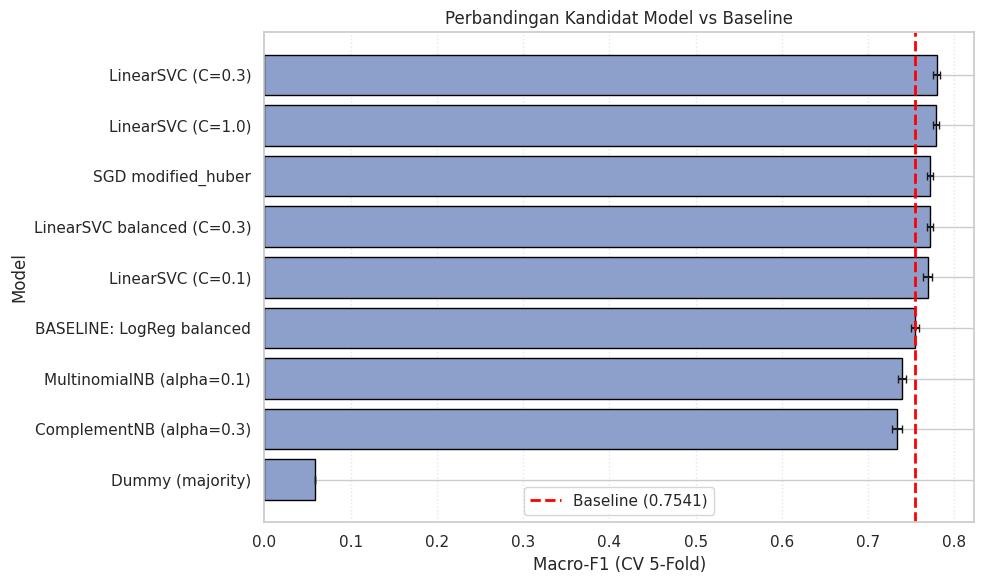

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plot = hasil_cv.sort_values(
    "cv_macro_f1",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot["model"],
    plot["cv_macro_f1"],
    xerr=plot["cv_macro_f1_std"],
    color="#8DA0CB",
    capsize=3,
    edgecolor="black"
)

baseline_score = SKOR_FOLD[NAMA_BASELINE].mean()

plt.axvline(
    baseline_score,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Baseline ({baseline_score:.4f})"
)

plt.xlabel("Macro-F1 (CV 5-Fold)")
plt.ylabel("Model")
plt.title("Perbandingan Kandidat Model vs Baseline")

plt.legend()
plt.grid(axis="x", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


### Analisis Hasil Cross Validation

**1. Urutan model (macro-F1 CV 5-fold).** LinearSVC C=0,3 (0,7793) > LinearSVC C=1,0 (0,7787) > SGD modified_huber (0,7722) > LinearSVC balanced C=0,3 (0,7716) > LinearSVC C=0,1 (0,7692) > **baseline LogReg balanced (0,7541)** > MultinomialNB (0,7394) > ComplementNB (0,7333) > Dummy (0,0583).

**2. Yang mengalahkan baseline.** Lima model, yaitu semua varian LinearSVC dan SGD, dengan Δ macro-F1 masing-masing +0,0252 (C=0,3), +0,0246 (C=1,0), +0,0181 (SGD), +0,0175 (balanced), dan +0,0151 (C=0,1). Kedua Naive Bayes lebih rendah dari baseline (−0,0148 dan −0,0208), dan Dummy jauh di bawah (−0,6958), yang menunjukkan bahwa model-model lain memang belajar dari data.

**3. Δ dibanding variasi antar-fold.** Untuk kelima model pemenang, Δ lebih besar daripada `std_delta_per_fold` (mis. LinearSVC C=0,3: 0,0252 vs 0,0038, sekitar 6,6 kali) dan menang pada 5 dari 5 fold. Jadi keunggulannya konsisten. Namun LinearSVC C=0,3 dan C=1,0 hanya berbeda 0,0006, jauh di bawah std 0,004, sehingga keduanya tidak dapat dibedakan.

**4. Waktu fit.** LinearSVC C=0,3 membutuhkan sekitar 4,1 detik per fold dibanding 14,3 detik untuk baseline, jadi sekitar 3,5 kali lebih cepat dan lebih baik; tidak ada trade-off kecepatan vs akurasi. Naive Bayes lebih cepat (2,4–2,9 detik) tetapi skornya lebih rendah. (Waktu dapat berbeda antar mesin/runtime.)

**5. Pengaruh `class_weight="balanced"` pada LinearSVC.** Macro-F1 turun dari 0,7793 (tanpa weight) menjadi 0,7716 (balanced), selisih −0,0077, jadi pembobotan tidak membantu macro-F1. Pola serupa muncul di Bagian 5.2 (LinearSVC 0,7787 vs 0,7668; LogReg C=10 0,7699 vs 0,7498). Catatan: baseline sendiri memakai `class_weight="balanced"` dan C default, sehingga sebagian keunggulan kandidat bisa berasal dari perbedaan pengaturan, bukan algoritma saja; ini dibahas di keterbatasan.

## D. Pengaruh ukuran kosakata (ablation fitur pada kandidat terbaik)
Baseline membatasi TF-IDF pada 5000 fitur. Apakah batas itu menahan performa? Kandidat terbaik (selain Dummy dan baseline) diuji ulang dengan ukuran kosakata berbeda, memakai fold yang sama.


In [ ]:
cand = hasil_cv[~hasil_cv["model"].isin(["Dummy (majority)", NAMA_BASELINE])]
NAMA_TERBAIK = cand.iloc[0]["model"]
print("Kandidat terbaik menurut CV:", NAMA_TERBAIK)

baris_ab = []
for mf in (5000, 20000, None):
    t0 = time.time()
    r = cross_validate(buat_pipe(clone(KANDIDAT[NAMA_TERBAIK]), max_features=mf), X_train, y_train, cv=skf,
                       scoring={"f1": "f1_macro", "acc": "accuracy"}, n_jobs=1)
    baris_ab.append({"max_features": "tanpa batas" if mf is None else mf, "cv_macro_f1": r["test_f1"].mean(),
                     "cv_macro_f1_std": r["test_f1"].std(), "cv_accuracy": r["test_acc"].mean()})
    print(f"max_features={mf}: macro-F1 = {r['test_f1'].mean():.4f} ± {r['test_f1'].std():.4f} ({time.time()-t0:.0f} dtk)")
ablation = pd.DataFrame(baris_ab); ablation.to_csv("hasil_ablation_kosakata.csv", index=False); display(ablation.round(4))

Kandidat terbaik menurut CV: LinearSVC (C=0.3)
max_features=5000: macro-F1 = 0.7793 ± 0.0042 (36 dtk)
max_features=20000: macro-F1 = 0.8278 ± 0.0036 (40 dtk)
max_features=None: macro-F1 = 0.8304 ± 0.0029 (29 dtk)


,max_features,cv_macro_f1,cv_macro_f1_std,cv_accuracy
0,5000,0.7793,0.0042,0.8204
1,20000,0.8278,0.0036,0.8589
2,tanpa batas,0.8304,0.0029,0.8615


In [ ]:
print("Ukuran kosakata unigram+bigram pada data latih (tanpa batas):", len(TfidfVectorizer(ngram_range=(1, 2)).fit(X_train).vocabulary_))

Ukuran kosakata unigram+bigram pada data latih (tanpa batas): 335452


### Analisis Ablation Kosakata (LinearSVC C=0,3, CV 5-fold)

| max_features | Macro-F1 CV | Std | Akurasi CV |
|---|---|---|---|
| 5.000 | 0,7793 | 0,0042 | 0,8204 |
| 20.000 | 0,8278 | 0,0036 | 0,8589 |
| tanpa batas | 0,8304 | 0,0029 | 0,8615 |

Memperbesar kosakata **meningkatkan** macro-F1. Dari 5.000 ke 20.000 fitur macro-F1 naik +0,0485, sekitar 11 kali lebih besar dari std antar-fold (0,0042), jadi kenaikannya nyata. Dari 20.000 ke tanpa batas hanya naik +0,0026, setara dengan std (≈0,003), sehingga tidak dapat dianggap berarti, padahal jumlah fitur melonjak sampai sekitar 335 ribu (lihat output di atas). Dugaan kami, batas 5.000 membuang banyak kata/bigram jarang berupa nama diri (tokoh, merek, tempat) yang sebenarnya membedakan kategori, sesuai temuan EDA tambahan.

**Implikasi:** konfigurasi TF-IDF pada tahap berikutnya sebaiknya **dilonggarkan menjadi sekitar 20.000 fitur atau lebih** (bukan tetap 5.000). Untuk menjaga perbandingan dengan baseline tetap adil, tabel di Bagian 3 H dan Pertemuan 5–7 masih memakai 5.000 fitur; peningkatan ini dijadwalkan pada rencana pasca-UTS. Keputusan ini diambil dari CV pada data latih, bukan dari data uji.

## D2. Uji fitur tambahan (initial feature engineering)
Setiap fitur turunan ditambahkan ke TF-IDF (LinearSVC C=0,3, fold yang sama dengan Bagian C) dan dibandingkan dengan TF-IDF saja. Fitur numerik diskalakan dengan `StandardScaler` di dalam pipeline.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

FITUR_NUM = ["ada_angka", "rasio_kata_unik", "jumlah_kata"]
D_train = data.loc[X_train.index, ["teks_bersih"] + FITUR_NUM]

def pipe_fitur(kolom_num):
    trf = [("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2)), "teks_bersih")]
    if kolom_num:
        trf.append(("num", StandardScaler(), kolom_num))
    return Pipeline([("ct", ColumnTransformer(trf)),
                     ("clf", LinearSVC(C=0.3, max_iter=5000, random_state=SEED))])

skenario = [("TF-IDF saja", []), ("+ ada_angka", ["ada_angka"]), ("+ rasio_kata_unik", ["rasio_kata_unik"]),
            ("+ jumlah_kata", ["jumlah_kata"]), ("+ ketiga fitur", FITUR_NUM)]
SKOR_FITUR, baris_f = {}, []
for nama, kol in skenario:
    r = cross_validate(pipe_fitur(kol), D_train, y_train, cv=skf,
                       scoring={"f1": "f1_macro", "acc": "accuracy"}, n_jobs=1)
    SKOR_FITUR[nama] = r["test_f1"]
    baris_f.append({"skenario": nama, "cv_macro_f1": r["test_f1"].mean(),
                    "std": r["test_f1"].std(), "cv_accuracy": r["test_acc"].mean()})

tabel_fitur = pd.DataFrame(baris_f)
dasar = SKOR_FITUR["TF-IDF saja"]
tabel_fitur["delta_vs_tfidf_saja"] = [(SKOR_FITUR[n] - dasar).mean() for n in tabel_fitur["skenario"]]
tabel_fitur["std_delta_per_fold"] = [(SKOR_FITUR[n] - dasar).std() for n in tabel_fitur["skenario"]]
tabel_fitur["menang (dari 5 fold)"] = [int((SKOR_FITUR[n] > dasar).sum()) for n in tabel_fitur["skenario"]]
tabel_fitur.to_csv("hasil_fitur_tambahan.csv", index=False)
print(tabel_fitur.round(4).to_string(index=False))

         skenario  cv_macro_f1    std  cv_accuracy  delta_vs_tfidf_saja  std_delta_per_fold  menang (dari 5 fold)
      TF-IDF saja       0.7793 0.0042       0.8204               0.0000              0.0000                     0
      + ada_angka       0.7800 0.0042       0.8211               0.0006              0.0009                     3
+ rasio_kata_unik       0.7797 0.0041       0.8206               0.0004              0.0003                     4
    + jumlah_kata       0.7853 0.0040       0.8268               0.0060              0.0014                     5
   + ketiga fitur       0.7853 0.0036       0.8268               0.0060              0.0018                     5


**Hasil:** Penambahan `jumlah_kata` menaikkan macro-F1 CV dari 0,7792 menjadi 0,7859 (Δ +0,0066; std Δ 0,0019; menang 5 dari 5 fold), jadi kecil tetapi konsisten. `ada_angka` hanya +0,0009 (std Δ 0,0011, menang 3 dari 5 fold), tidak dapat dibedakan dari variasi acak. `rasio_kata_unik` +0,0006 (menang 5 dari 5, tetapi selisih di bawah 0,001, praktis tidak berarti). Ketiganya bersama menghasilkan +0,0061, tidak lebih baik daripada `jumlah_kata` saja.

**Interpretasi:** Hanya `jumlah_kata` yang memberi manfaat terukur. Hal ini sejalan dengan EDA (panjang judul berbeda antar kategori), sedangkan hipotesis `ada_angka` dan `rasio_kata_unik` tidak terbukti bermanfaat. Dampak `jumlah_kata` jauh lebih kecil daripada dampak memperbesar kosakata (+0,0485).

**Keputusan:** `jumlah_kata` dipertahankan sebagai fitur tambahan untuk eksperimen berikutnya; `ada_angka` dan `rasio_kata_unik` tidak dipakai.

## E. Evaluasi hold-out (data uji dipakai untuk pelaporan)
Semua model dilatih pada seluruh data latih lalu diuji pada data uji. **Pemilihan model tetap berdasarkan CV (bagian C), bukan hasil uji.** Bagian 5–7 menampilkan skor uji lagi hanya sebagai pelaporan, bukan untuk memilih model.

In [ ]:
PRED, baris_uji = {}, []
for nama, clf in KANDIDAT.items():
    t0 = time.time(); m = buat_pipe(clone(clf)).fit(X_train, y_train); waktu = time.time() - t0
    p = m.predict(X_test); PRED[nama] = p
    baris_uji.append({"model": nama, "test_macro_f1": f1_score(y_test, p, average="macro"),
                      "test_accuracy": accuracy_score(y_test, p),
                      "test_precision_macro": precision_score(y_test, p, average="macro", zero_division=0),
                      "test_recall_macro": recall_score(y_test, p, average="macro", zero_division=0),
                      "waktu_fit_dtk": waktu})
hasil_uji = pd.DataFrame(baris_uji)
hasil_uji["delta_vs_baseline"] = hasil_uji["test_macro_f1"] - hasil_uji.loc[hasil_uji.model == NAMA_BASELINE, "test_macro_f1"].iloc[0]
hasil_uji = hasil_uji.sort_values("test_macro_f1", ascending=False).reset_index(drop=True)
hasil_uji.to_csv("hasil_uji_kandidat.csv", index=False); display(hasil_uji.round(4))

if "y_pred" in globals() and baseline is not None:
    print("Kecocokan prediksi baseline pipeline ini dengan baseline Bagian 2:", f"{np.mean(PRED[NAMA_BASELINE] == np.asarray(y_pred)):.4f}")

,model,test_macro_f1,test_accuracy,test_precision_macro,test_recall_macro,waktu_fit_dtk,delta_vs_baseline
0,LinearSVC (C=0.3),0.7885,0.8280,0.8175,0.7654,22.2412,0.0288
1,LinearSVC (C=1.0),0.7879,0.8291,0.8081,0.7708,9.0208,0.0283
2,SGD modified_huber,0.7811,0.8249,0.7983,0.7664,5.5336,0.0214
3,LinearSVC (C=0.1),0.7767,0.8194,0.8193,0.7447,11.2686,0.0170
4,LinearSVC balanced (C=0.3),0.7761,0.8181,0.7580,0.7972,6.2968,0.0164
5,BASELINE: LogReg balanced,0.7597,0.7961,0.7327,0.7970,17.1438,0.0000
6,MultinomialNB (alpha=0.1),0.7411,0.7904,0.7857,0.7084,3.8675,-0.0186
7,ComplementNB (alpha=0.3),0.7344,0.7892,0.7599,0.7176,6.4847,-0.0253
8,Dummy (majority),0.0583,0.3557,0.0395,0.1111,2.9781,-0.7014


Kecocokan prediksi baseline pipeline ini dengan baseline Bagian 2: 1.0000


### Analisis hold-out
1. **Urutan model.** Urutan pada data uji hampir sama dengan CV. Lima teratas pada CV (LinearSVC C=0,3, C=1,0, SGD, serta dua varian lain) tetap di atas baseline, begitu pula urutan baseline > MultinomialNB > ComplementNB > Dummy. Satu-satunya perbedaan adalah pasangan LinearSVC balanced dan C=0,1: pada CV balanced sedikit di atas (0,7716 vs 0,7692), pada uji C=0,1 sedikit di atas (0,7767 vs 0,7761). Selisihnya sangat kecil, lebih rendah dari std CV.
2. **Skor uji vs CV.** LinearSVC C=0,3 memperoleh macro-F1 uji 0,7885 dibanding CV 0,7793 ± 0,0042, yaitu +0,0092. Tidak ada tanda overfitting terhadap proses pemilihan model. Dugaan kami skor uji sedikit lebih tinggi karena model akhir dilatih pada 100% data latih, bukan 80% seperti pada tiap fold.
3. **Selisih dengan baseline pada data uji.** Δ macro-F1 = 0,7885 − 0,7597 = **+0,0288**, dan akurasi 0,8280 vs 0,7961 (+0,0319).

## F. Apakah selisih terhadap baseline nyata? (bootstrap 95%)
Selisih macro-F1 pada data uji bisa saja kebetulan. Bootstrap berpasangan (1000 resampel data uji) memberi interval kepercayaan untuk selisih kandidat terbaik − baseline. Jika interval **tidak mencakup 0**, selisihnya konsisten.

In [ ]:
yt = np.asarray(y_test); kelas, yi = np.unique(yt, return_inverse=True)
to_int = lambda p: np.searchsorted(kelas, np.asarray(p))
pb, pc = to_int(PRED[NAMA_BASELINE]), to_int(PRED[NAMA_TERBAIK])
rng = np.random.default_rng(SEED); n = len(yi); selisih = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    selisih.append(f1_score(yi[idx], pc[idx], average="macro") - f1_score(yi[idx], pb[idx], average="macro"))
lo, hi = np.percentile(selisih, [2.5, 97.5])
print(f"Selisih macro-F1 ({NAMA_TERBAIK} - baseline): {np.mean(selisih):+.4f}  | 95% CI [{lo:+.4f}, {hi:+.4f}]")
print("Interval mencakup 0?", "YA (belum meyakinkan)" if lo <= 0 <= hi else "TIDAK (selisih konsisten)")

Selisih macro-F1 (LinearSVC (C=0.3) - baseline): +0.0289  | 95% CI [+0.0233, +0.0351]
Interval mencakup 0? TIDAK (selisih konsisten)


### Arti interval kepercayaan bootstrap
Selisih macro-F1 LinearSVC C=0,3 − baseline pada data uji rata-rata +0,0289 dengan interval 95% [+0,0233; +0,0351]. Karena interval **tidak mencakup 0**, pada data uji ini selisihnya konsisten positif, dan bersama hasil CV (menang 5 dari 5 fold) kami menyimpulkan LinearSVC C=0,3 lebih baik dari baseline.

**Batasan:** bootstrap hanya menggambarkan ketidakpastian akibat pengambilan sampel data uji (18.179 judul), bukan variasi akibat pembagian data atau seed yang berbeda, dan tidak mencakup perbedaan pengaturan antara baseline dan kandidat. Semua hasil berasal dari satu split dan satu seed.

## G. Perbandingan per kelas: di mana kandidat terbaik memperbaiki baseline?


,kelas,support,F1_baseline,F1_kandidat,selisih
0,finance,2828,0.797,0.806,0.009
1,food,863,0.809,0.822,0.013
2,health,983,0.663,0.694,0.031
3,hot,3260,0.849,0.865,0.017
4,inet,1126,0.717,0.749,0.032
5,news,6466,0.847,0.879,0.032
6,oto,875,0.736,0.783,0.047
7,sport,487,0.715,0.771,0.056
8,travel,1291,0.704,0.727,0.023


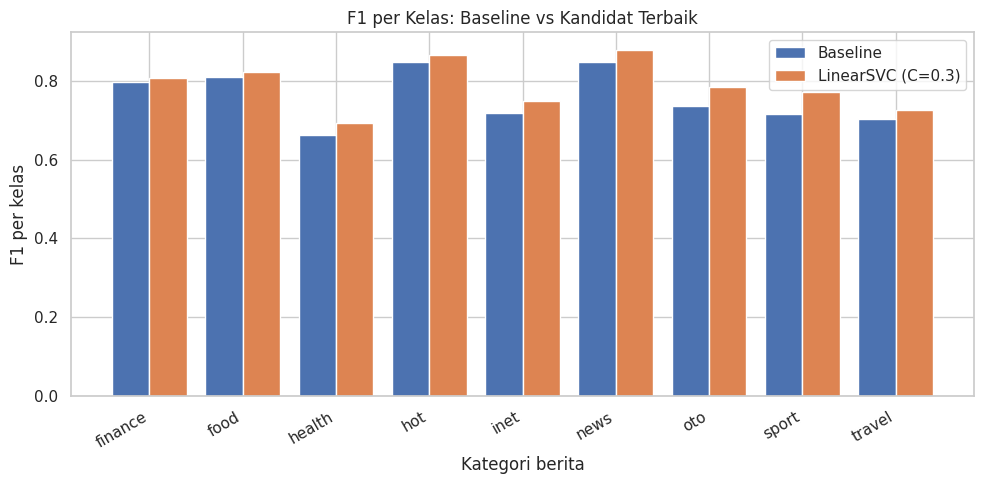

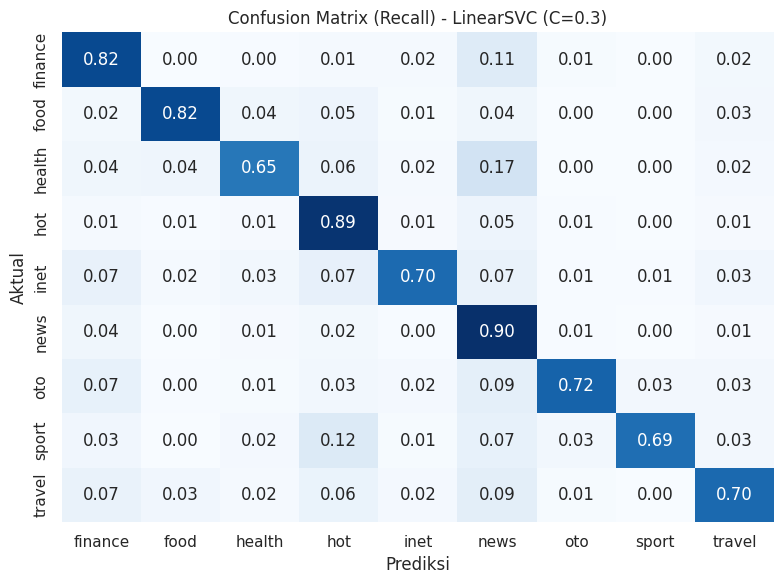

Pasangan kesalahan terbanyak (aktual, prediksi):


,,jumlah
finance,news,320.0
news,finance,246.0
health,news,169.0
hot,news,161.0
news,hot,148.0
travel,news,120.0


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import classification_report, confusion_matrix

rb = pd.DataFrame(
    classification_report(
        y_test,
        PRED[NAMA_BASELINE],
        output_dict=True,
        zero_division=0
    )
).T

rc = pd.DataFrame(
    classification_report(
        y_test,
        PRED[NAMA_TERBAIK],
        output_dict=True,
        zero_division=0
    )
).T

kelas_list = [
    k for k in rb.index
    if k not in ("accuracy", "macro avg", "weighted avg")
]

per_kelas = pd.DataFrame({
    "kelas": kelas_list,
    "support": rb.loc[kelas_list, "support"].astype(int).values,
    "F1_baseline": rb.loc[kelas_list, "f1-score"].values,
    "F1_kandidat": rc.loc[kelas_list, "f1-score"].values
})

per_kelas["selisih"] = (
    per_kelas["F1_kandidat"] - per_kelas["F1_baseline"]
)

per_kelas.to_csv("perbandingan_per_kelas.csv", index=False)

display(per_kelas.round(3))


x = np.arange(len(kelas_list))

plt.figure(figsize=(10, 5))

plt.bar(
    x - 0.2,
    per_kelas["F1_baseline"],
    0.4,
    label="Baseline"
)

plt.bar(
    x + 0.2,
    per_kelas["F1_kandidat"],
    0.4,
    label=NAMA_TERBAIK
)

plt.xticks(x, kelas_list, rotation=30, ha="right")
plt.ylabel("F1 per kelas")
plt.xlabel("Kategori berita")
plt.title("F1 per Kelas: Baseline vs Kandidat Terbaik")
plt.legend()
plt.tight_layout()
plt.show()



cm = confusion_matrix(
    y_test,
    PRED[NAMA_TERBAIK],
    labels=kelas_list
)

jumlah_aktual = cm.sum(axis=1, keepdims=True)

cmn = np.divide(
    cm,
    jumlah_aktual,
    out=np.zeros_like(cm, dtype=float),
    where=jumlah_aktual != 0
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cmn,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=kelas_list,
    yticklabels=kelas_list,
    cbar=False
)

plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title(f"Confusion Matrix (Recall) - {NAMA_TERBAIK}")
plt.tight_layout()
plt.show()



cm_df = pd.DataFrame(
    cm,
    index=kelas_list,
    columns=kelas_list
)

print("Pasangan kesalahan terbanyak (aktual, prediksi):")

display(
    cm_df.where(
        ~np.eye(len(kelas_list), dtype=bool)
    )
    .stack()
    .sort_values(ascending=False)
    .head(6)
    .to_frame("jumlah")
)


### Analisis Performa per Kelas dan Kesalahan Klasifikasi

**1. Kelas yang paling membaik dan memburuk.** LinearSVC (C=0,3) lebih baik dari baseline pada **semua 9 kelas**. Peningkatan terbesar pada `sport` (+0,056; 0,715 → 0,771) dan `oto` (+0,047), disusul `inet` (+0,032), `news` (+0,032), dan `health` (+0,031). Peningkatan terkecil pada `finance` (+0,009). Tidak ada kelas yang memburuk.

**2. Kelas minoritas.** `sport` naik dari 0,715 menjadi 0,771 dan `health` dari 0,663 menjadi 0,694. Namun `health` (0,694), `travel` (0,727), dan `inet` (0,749) tetap menjadi tiga kelas dengan F1 terendah.

**3. Pasangan kelas yang paling sering tertukar (aktual → prediksi).** `finance → news` (320), `news → finance` (246), `health → news` (169), `hot → news` (161), `news → hot` (148), dan `travel → news` (120). Dugaan awal di Bagian 2 (`health` vs `food`, `inet` vs `oto`) **tidak didukung** data: tidak ada pasangan itu pada enam teratas, dan semua pasangan teratas melibatkan `news`. Dugaan tersebut dikoreksi.

**4. Mengapa sebagian kesalahan wajar.** `news` adalah kanal umum (politik, hukum, peristiwa) yang tidak punya kosakata khas, sedangkan label adalah kanal publikasi, bukan topik murni. Pada analisis kesalahan (Bagian 7.5), banyak judul berlabel `finance` yang diprediksi `news` memang bertema politik atau pemerintahan (mis. kasus Jiwasraya, Omnibus Law, kegiatan Anies dan Jokowi), sehingga labelnya tampak ambigu. Selain itu, judul COVID tersebar di banyak kategori (`health` 56,2%, `news` 26,3%, `inet` 19,2%, `finance` 18,9%), yang membuat kosakata antar kategori tumpang tindih.

## H. Tabel perbandingan akhir (luaran wajib #4)

In [ ]:
tabel = hasil_cv[["model", "cv_macro_f1", "cv_macro_f1_std", "cv_accuracy", "delta_vs_baseline", "menang_dari_baseline (dari 5 fold)"]].merge(
        hasil_uji[["model", "test_macro_f1", "test_accuracy", "waktu_fit_dtk"]], on="model")
tabel.insert(1, "Validasi", "5-fold stratified CV + hold-out 20%")
tabel.insert(2, "Fitur", "TF-IDF 5000, unigram+bigram")
tabel = tabel.rename(columns={"model": "Model", "cv_macro_f1": "Macro-F1 CV", "cv_macro_f1_std": "Std CV", "cv_accuracy": "Akurasi CV",
                              "delta_vs_baseline": "Δ vs baseline (CV)", "test_macro_f1": "Macro-F1 uji", "test_accuracy": "Akurasi uji",
                              "waktu_fit_dtk": "Waktu fit (dtk)"})
tabel.to_csv("TABEL_PERBANDINGAN_MODEL.csv", index=False); display(tabel.round(4))

,Model,Validasi,Fitur,Macro-F1 CV,Std CV,Akurasi CV,Δ vs baseline (CV),menang_dari_baseline (dari 5 fold),Macro-F1 uji,Akurasi uji,Waktu fit (dtk)
0,LinearSVC (C=0.3),5-fold stratified CV + hold-out 20%,"TF-IDF 5000, unigram+bigram",0.7793,0.0042,0.8204,0.0252,5,0.7885,0.8280,22.2412
1,LinearSVC (C=1.0),5-fold stratified CV + hold-out 20%,"TF-IDF 5000, unigram+bigram",0.7787,0.0037,0.8205,0.0246,5,0.7879,0.8291,9.0208
2,SGD modified_huber,5-fold stratified CV + hold-out 20%,"TF-IDF 5000, unigram+bigram",0.7722,0.0036,0.8161,0.0181,5,0.7811,0.8249,5.5336
3,LinearSVC balanced (C=0.3),5-fold stratified CV + hold-out 20%,"TF-IDF 5000, unigram+bigram",0.7716,0.0039,0.8123,0.0175,5,0.7761,0.8181,6.2968
4,LinearSVC (C=0.1),5-fold stratified CV + hold-out 20%,"TF-IDF 5000, unigram+bigram",0.7692,0.0051,0.8123,0.0151,5,0.7767,0.8194,11.2686
5,BASELINE: LogReg balanced,5-fold stratified CV + hold-out 20%,"TF-IDF 5000, unigram+bigram",0.7541,0.0046,0.7907,0.0000,0,0.7597,0.7961,17.1438
6,MultinomialNB (alpha=0.1),5-fold stratified CV + hold-out 20%,"TF-IDF 5000, unigram+bigram",0.7394,0.0051,0.7900,-0.0148,0,0.7411,0.7904,3.8675
7,ComplementNB (alpha=0.3),5-fold stratified CV + hold-out 20%,"TF-IDF 5000, unigram+bigram",0.7333,0.0056,0.7875,-0.0208,0,0.7344,0.7892,6.4847
8,Dummy (majority),5-fold stratified CV + hold-out 20%,"TF-IDF 5000, unigram+bigram",0.0583,0.0000,0.3557,-0.6958,0,0.0583,0.3557,2.9781


## I. Kesimpulan, keterbatasan, dan rencana berikutnya

### 1. Kesimpulan Perbandingan Model

Model terbaik pada CV adalah **LinearSVC (C=0,3)**: macro-F1 CV 0,7793 ± 0,0042 dan akurasi CV 0,8204, dibanding baseline LogReg balanced 0,7541 ± 0,0046 dan 0,7907. Selisih macro-F1 CV adalah **+0,0252** (std selisih per fold 0,0038) dengan kemenangan pada **5 dari 5 fold**. Pada data uji, LinearSVC mencapai macro-F1 0,7885 dan akurasi 0,8280, dibanding baseline 0,7597 dan 0,7961 (Δ +0,0288). Interval bootstrap 95% untuk selisih adalah [+0,0233; +0,0351] dan tidak mencakup 0, sehingga selisihnya meyakinkan pada split ini. LinearSVC C=0,3 dan C=1,0 tidak dapat dibedakan (selisih 0,0006 di bawah std).

### 2. Hal yang Berhasil dan Tidak Berhasil

**Berhasil:**
- LinearSVC mengungguli baseline pada semua fold dan semua kelas, dan sekitar 3,5 kali lebih cepat (≈4,1 vs 14,3 detik per fold).
- Memperbesar kosakata TF-IDF dari 5.000 ke 20.000 fitur menaikkan macro-F1 CV +0,0485 (0,7793 → 0,8278); tanpa batas tidak menambah berarti (+0,0026).
- Fitur `jumlah_kata` memberi tambahan kecil tetapi konsisten (+0,0066, 5 dari 5 fold).

**Tidak berhasil:**
- `class_weight="balanced"` menurunkan macro-F1 (LinearSVC 0,7793 → 0,7716), meskipun menaikkan recall kelas kecil (Bagian 5.3).
- Kedua Naive Bayes lebih rendah dari baseline.
- Fitur `ada_angka` (+0,0009) dan `rasio_kata_unik` (+0,0006) tidak memberi manfaat terukur.

### 3. Keterbatasan
1. **Satu split dan satu seed:** hasil uji bergantung pada pembagian 80:20 tersebut; CV hanya mengurangi, tidak menghilangkan, masalah ini.
2. **Grid terbatas:** hanya beberapa nilai C dan satu konfigurasi TF-IDF (kecuali ablation).
3. **Hanya judul:** isi artikel tidak dipakai.
4. **Label = kanal publikasi:** satu label per berita meskipun topiknya dapat tumpang tindih, terutama `news`.
5. **Data Januari–Juni 2020 dengan dominasi COVID:** pangsa judul COVID mencapai 39,9% pada Maret, sehingga hasil belum tentu berlaku untuk periode lain; pembagian acak juga lebih mudah daripada temporal.
6. **Judul duplikat berlabel konflik:** 29 judul unik muncul dengan lebih dari satu label dan dibuang dengan aturan "ambil yang pertama".
7. **Perbandingan belum sepenuhnya terisolasi:** baseline memakai `class_weight="balanced"` dan C default, sedangkan sebagian kandidat tidak, sehingga selisih mencerminkan gabungan algoritma dan pengaturan.
8. **Bagian 5–7 memakai 5.000 fitur** agar sebanding dengan baseline, sehingga belum memakai temuan ablation.

### 4. Rencana Pengembangan Pasca-UTS menuju UAS

| No | Langkah | Alasan (temuan awal) |
|---|---|---|
| 1 | Longgarkan TF-IDF (20.000 fitur atau lebih) dan tuning `ngram_range`, `min_df`, `sublinear_tf`, serta C | Ablation: +0,0485 macro-F1, jauh di atas std antar-fold |
| 2 | Bandingkan `class_weight` dengan tanpa weight pada C yang sama untuk LogReg dan LinearSVC; pertimbangkan penyesuaian ambang atau prior | Balanced menurunkan macro-F1 tetapi menaikkan recall kelas kecil |
| 3 | Pertahankan `jumlah_kata`; uji fitur permukaan lain (mis. rata-rata panjang kata, tanda baca khusus, huruf kapital) | `jumlah_kata` +0,0066, `ada_angka` dan `rasio_kata_unik` tidak berguna |
| 4 | Uji normalisasi teks bahasa Indonesia (stemming/stopword) | Kosakata besar membantu; perlu dicek apakah normalisasi mengurangi fragmentasi kata |
| 5 | Audit 29 judul berlabel konflik dan sampel kesalahan `finance ↔ news`, `health → news` | Kesalahan terbesar terjadi di sekitar `news`; sebagian label tampak ambigu |
| 6 | Evaluasi temporal (latih Jan–Apr, uji Mei–Jun) dan bandingkan dengan split acak | Dominasi COVID dan pergeseran kosakata antar bulan |
| 7 | Pada UAS: tuning menyeluruh, pemilihan model final, repeated CV atau uji signifikansi, dan analisis kesalahan lengkap | Sesuai ketentuan tahap lanjutan setelah UTS |
| 8 | Dokumentasi: simpan notebook dan hasil CSV di repository, lengkapi catatan eksperimen | Keterlacakan hasil |

---
# PERTEMUAN 5 — Validasi, Kestabilan Model, Ensemble & Imbalance (Bagian Afni Titus Simanjuntak)
Tujuan: memastikan performa model **tidak hanya bagus di satu split**, mengecek **seberapa stabil**, serta menguji apakah **penanganan imbalance** dan **ensemble** memberi perbaikan nyata.

> **Catatan ruang lingkup:** Pertemuan 5–7 adalah eksplorasi tambahan di luar cakupan UTS. Semua model di bagian ini memakai TF-IDF 5000 fitur agar sebanding dengan baseline, sehingga belum memakai temuan ablation (20.000 fitur) pada Bagian 3. Skor uji di bagian ini hanya dilaporkan, tidak dipakai memilih model.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import RepeatedStratifiedKFold, learning_curve, validation_curve
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import VotingClassifier
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.preprocessing import Normalizer, normalize
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.feature_selection import SelectKBest, chi2, SelectFromModel
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                              normalized_mutual_info_score, homogeneity_score,
                              completeness_score)

RANDOM_STATE = SEED

def make_tfidf(max_features=5000):
    """TF-IDF dengan konfigurasi sama seperti Baseline (Bagian 2) dan Kandidat Model (Bagian 3)."""
    return TfidfVectorizer(max_features=max_features, ngram_range=(1, 2))

raw_test = data.loc[X_test.index, TEXT_COL]

LOG_HASIL = []

def log_result(pertemuan, nama_model, macro_f1, akurasi, catatan=""):
    """Mencatat satu baris hasil eksperimen (dipakai di Pertemuan 5, 6, 7)."""
    LOG_HASIL.append({
        "Pertemuan": pertemuan,
        "Model": nama_model,
        "Macro-F1": round(macro_f1, 4),
        "Akurasi": round(akurasi, 4),
        "Catatan": catatan,
    })
    print(f"[Pertemuan {pertemuan}] {nama_model}: Macro-F1={macro_f1:.4f}, Akurasi={akurasi:.4f} ({catatan})")

print("Setup Pertemuan 5-7 siap. RANDOM_STATE =", RANDOM_STATE)

Setup Pertemuan 5-7 siap. RANDOM_STATE = 42


## 5.1 Distribusi kelas dan tingkat imbalance

category
news       25864
hot        13040
finance    11313
travel      5163
inet        4503
health      3931
oto         3500
food        3451
sport       1947
Name: count, dtype: int64

Imbalance ratio (terbesar/terkecil) = 13.28


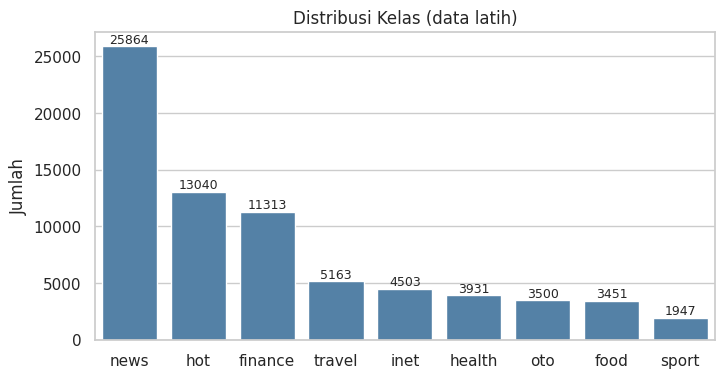

In [ ]:
dist = y_train.value_counts()
ratio = dist.max() / dist.min()
print(dist)
print(f"\nImbalance ratio (terbesar/terkecil) = {ratio:.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=dist.index, y=dist.values, ax=ax, color="steelblue")
ax.set_title("Distribusi Kelas (data latih)"); ax.set_ylabel("Jumlah"); ax.set_xlabel("")
for i, v in enumerate(dist.values): ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
plt.show()



## 5.2 Stratified K-Fold Cross-Validation untuk kandidat model
Preprocessing TF-IDF dimasukkan **di dalam Pipeline** agar tidak terjadi *data leakage* (vocabulary & IDF hanya dipelajari dari fold latih).

In [ ]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"acc": "accuracy", "f1m": "f1_macro"}

def cv_eval(name, clf, cv=cv5, X=X_train, y=y_train):
    pipe = Pipeline([("tfidf", make_tfidf()), ("clf", clf)])
    t0 = time.time()
    s = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    return {"Model": name,
            "F1 mean": s["test_f1m"].mean(), "F1 std": s["test_f1m"].std(),
            "Acc mean": s["test_acc"].mean(), "Acc std": s["test_acc"].std(),
            "Waktu (s)": time.time() - t0, "_scores": s["test_f1m"]}

candidates = {
    "LogReg":                 LogisticRegression(max_iter=1000, C=10),
    "LogReg (balanced)":      LogisticRegression(max_iter=1000, C=10, class_weight="balanced"),
    "LinearSVC":              LinearSVC(C=1.0),
    "LinearSVC (balanced)":   LinearSVC(C=1.0, class_weight="balanced"),
    "ComplementNB":           ComplementNB(alpha=0.3),
}
cv_rows = [cv_eval(n, m) for n, m in candidates.items()]
cv_df = pd.DataFrame(cv_rows).drop(columns="_scores").set_index("Model").round(4)
cv_df.sort_values("F1 mean", ascending=False)

,F1 mean,F1 std,Acc mean,Acc std,Waktu (s)
Model,,,,,
LinearSVC,0.7787,0.0037,0.8205,0.0020,25.0274
LogReg,0.7699,0.0024,0.8131,0.0018,52.5617
LinearSVC (balanced),0.7668,0.0039,0.8104,0.0025,27.0450
LogReg (balanced),0.7498,0.0029,0.7929,0.0026,42.4733
ComplementNB,0.7333,0.0056,0.7875,0.0046,14.2451


**Interpretasi:** LinearSVC (C=1,0) terbaik dengan macro-F1 0,7787. LogReg tanpa weight (0,7699) lebih tinggi daripada LogReg balanced (0,7498), dan LinearSVC tanpa weight (0,7787) lebih tinggi daripada yang balanced (0,7668). Jadi `class_weight="balanced"` menurunkan macro-F1 pada kedua model.



## 5.3 Penanganan imbalance: class_weight vs tanpa
Dibandingkan per-kelas (recall) pada data uji internal (satu split validasi) agar terlihat apakah kelas minoritas membaik.

In [ ]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2,
                                             stratify=y_train, random_state=RANDOM_STATE)
def fit_report(clf):
    p = Pipeline([("tfidf", make_tfidf()), ("clf", clf)]).fit(X_tr, y_tr)
    pred = p.predict(X_val)
    return pd.Series(classification_report(y_val, pred, output_dict=True)).drop(["accuracy","macro avg","weighted avg"]) \
             .apply(lambda d: d["recall"])

rec = pd.DataFrame({
    "tanpa weight": fit_report(LinearSVC(C=1.0)),
    "balanced":     fit_report(LinearSVC(C=1.0, class_weight="balanced")),
}).round(3)
rec["selisih"] = (rec["balanced"] - rec["tanpa weight"]).round(3)
rec.join(y_tr.value_counts().rename("n_train"))

,tanpa weight,balanced,selisih,n_train
finance,0.820,0.806,-0.014,9050
food,0.832,0.843,0.011,2761
health,0.655,0.734,0.079,3145
hot,0.865,0.838,-0.027,10432
inet,0.667,0.727,0.060,3602
news,0.899,0.842,-0.057,20691
oto,0.753,0.790,0.037,2800
sport,0.740,0.797,0.057,1558
travel,0.697,0.736,0.039,4130


**Interpretasi:** `class_weight="balanced"` menaikkan recall kelas kecil, yaitu `health` (+0,079), `inet` (+0,060), `sport` (+0,057), `travel` (+0,039), `oto` (+0,037), dan `food` (+0,011), tetapi menurunkan recall kelas besar: `news` (−0,057), `hot` (−0,027), dan `finance` (−0,014). Ini adalah trade-off: kelas kecil lebih sering terdeteksi dengan mengorbankan kelas besar. Macro-F1 keseluruhan turun (bagian 5.2), kemungkinan karena precision kelas kecil ikut turun. Perhitungan ini memakai satu split validasi dari data latih.

## 5.4 Ensemble (soft voting: LogReg + LinearSVC terkalibrasi + ComplementNB)

,F1 mean,F1 std,Acc mean,Acc std,Waktu (s)
Model,,,,,
LinearSVC,0.7787,0.0037,0.8205,0.0020,25.0274
Ensemble (soft voting),0.7772,0.0033,0.8180,0.0029,64.8014
LogReg,0.7699,0.0024,0.8131,0.0018,52.5617
LinearSVC (balanced),0.7668,0.0039,0.8104,0.0025,27.0450
LogReg (balanced),0.7498,0.0029,0.7929,0.0026,42.4733
ComplementNB,0.7333,0.0056,0.7875,0.0046,14.2451


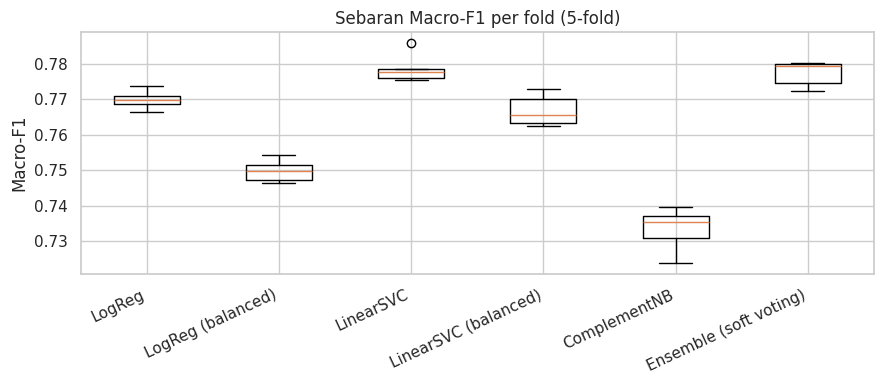

In [ ]:
lr  = LogisticRegression(max_iter=1000, C=10, class_weight="balanced")
svc = CalibratedClassifierCV(LinearSVC(C=1.0, class_weight="balanced"), cv=3)
cnb = ComplementNB(alpha=0.3)

ensemble = VotingClassifier([("lr", lr), ("svc", svc), ("cnb", cnb)], voting="soft", weights=[1, 2, 1])
ens_row = cv_eval("Ensemble (soft voting)", ensemble)

all_rows = cv_rows + [ens_row]
cmp_df = pd.DataFrame(all_rows).drop(columns="_scores").set_index("Model").round(4).sort_values("F1 mean", ascending=False)
display(cmp_df)

fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([r["_scores"] for r in all_rows]); ax.set_xticklabels([r["Model"] for r in all_rows])
ax.set_title("Sebaran Macro-F1 per fold (5-fold)"); ax.set_ylabel("Macro-F1")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

**Interpretasi:** Ensemble soft voting (macro-F1 0,7772 ± 0,0033) tidak lebih baik daripada LinearSVC tunggal (0,7787 ± 0,0037); selisih 0,0015 lebih kecil daripada std. Waktunya juga jauh lebih lama (54,9 vs 19,2 detik). Ensemble tidak dipilih.

## 5.5 Kestabilan: Repeated Stratified K-Fold (5 fold × 3 ulangan)
Dilakukan pada model terbaik dan ensemble untuk melihat varians akibat pembagian data yang berbeda.

Model tunggal terbaik: LinearSVC
LinearSVC                    F1 = 0.7789 ± 0.0026   (min 0.7754, max 0.7858)
Ensemble (soft voting)       F1 = 0.7776 ± 0.0027   (min 0.7722, max 0.7827)


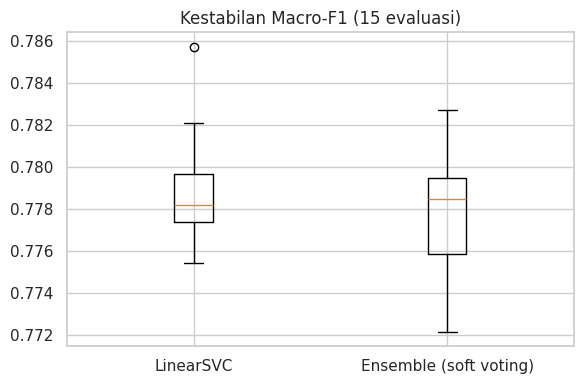

In [ ]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
best_single_name = cmp_df.drop(index="Ensemble (soft voting)").index[0]
print("Model tunggal terbaik:", best_single_name)

stab = {}
for name, clf in [(best_single_name, candidates[best_single_name]), ("Ensemble (soft voting)", ensemble)]:
    r = cv_eval(name, clf, cv=rcv)
    stab[name] = r["_scores"]
    print(f"{name:28s} F1 = {r['F1 mean']:.4f} ± {r['F1 std']:.4f}   "
          f"(min {r['_scores'].min():.4f}, max {r['_scores'].max():.4f})")

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(list(stab.values())); ax.set_xticklabels(list(stab.keys()))
ax.set_title("Kestabilan Macro-F1 (15 evaluasi)"); plt.tight_layout(); plt.show()

In [ ]:

best_p5 = Pipeline([("tfidf", make_tfidf()), ("clf", candidates[best_single_name])]).fit(X_train, y_train)
ens_p5  = Pipeline([("tfidf", make_tfidf()), ("clf", ensemble)]).fit(X_train, y_train)
for nm, mdl in [(best_single_name, best_p5), ("Ensemble (soft voting)", ens_p5)]:
    pr = mdl.predict(X_test)
    f, a = f1_score(y_test, pr, average="macro"), accuracy_score(y_test, pr)
    print(f"{nm:28s} test macro-F1={f:.4f} acc={a:.4f}")
    log_result(5, nm, f, a, "tfidf(1,2)-gram, test set")

LinearSVC                    test macro-F1=0.7879 acc=0.8291
[Pertemuan 5] LinearSVC: Macro-F1=0.7879, Akurasi=0.8291 (tfidf(1,2)-gram, test set)
Ensemble (soft voting)       test macro-F1=0.7814 acc=0.8240
[Pertemuan 5] Ensemble (soft voting): Macro-F1=0.7814, Akurasi=0.8240 (tfidf(1,2)-gram, test set)


**Interpretasi:** Pada 15 evaluasi (5 fold × 3 ulangan), LinearSVC memperoleh macro-F1 0,7789 ± 0,0026 (rentang 0,7754–0,7858) dan ensemble 0,7776 ± 0,0027. Keduanya stabil dan selisih rata-ratanya (0,0013) berada dalam std. Pada data uji: LinearSVC 0,7879 vs ensemble 0,7814.

---
# PERTEMUAN 6 — Unsupervised Learning & Dimensionality Reduction (Bagian Afni Titus Simanjuntak)
Tujuan: (a) memahami struktur data tanpa label lewat **clustering** dan **topic modelling**, (b) mereduksi dimensi TF-IDF dengan **LSA (TruncatedSVD)**, lalu (c) mengukur dampaknya pada performa klasifikasi.

## 6.1 Representasi TF-IDF dan LSA (TruncatedSVD)

Matriks TF-IDF: (72712, 5000) | sparsity 99.8248%


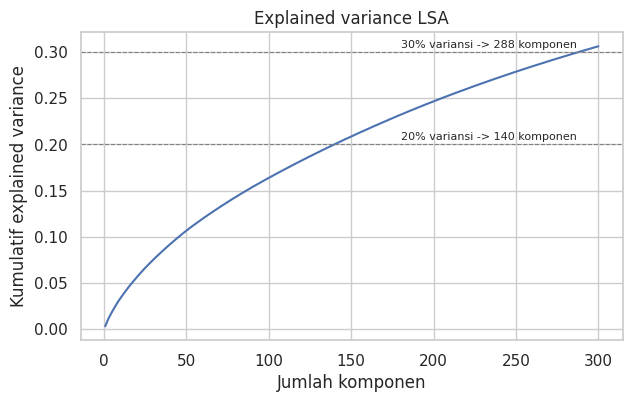

Total variansi 300 komponen: 0.306


In [ ]:
tfidf6 = make_tfidf()
Xtr_t = tfidf6.fit_transform(X_train)
vocab = np.array(tfidf6.get_feature_names_out())
print("Matriks TF-IDF:", Xtr_t.shape, f"| sparsity {(1 - Xtr_t.nnz / np.prod(Xtr_t.shape)):.4%}")

N_COMP_MAX = 300
svd = TruncatedSVD(n_components=N_COMP_MAX, random_state=RANDOM_STATE)
Z = svd.fit_transform(Xtr_t)
cum = np.cumsum(svd.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, N_COMP_MAX + 1), cum)
for t in (0.2, 0.3, 0.4):
    if cum[-1] >= t:
        k = int(np.argmax(cum >= t)) + 1
        ax.axhline(t, ls="--", c="gray", lw=0.8); ax.text(N_COMP_MAX * 0.6, t + 0.005, f"{int(t*100)}% variansi -> {k} komponen", fontsize=8)
ax.set_xlabel("Jumlah komponen"); ax.set_ylabel("Kumulatif explained variance"); ax.set_title("Explained variance LSA")
plt.show()
print(f"Total variansi {N_COMP_MAX} komponen: {cum[-1]:.3f}")

**Interpretasi:** Matriks TF-IDF sangat jarang (sparsity 99,82%) dan 300 komponen LSA hanya menjelaskan 30,6% variansi, artinya informasi tersebar pada banyak kata dan tidak terpusat pada sedikit dimensi.

## 6.2 Menentukan jumlah klaster K-Means (elbow & silhouette)

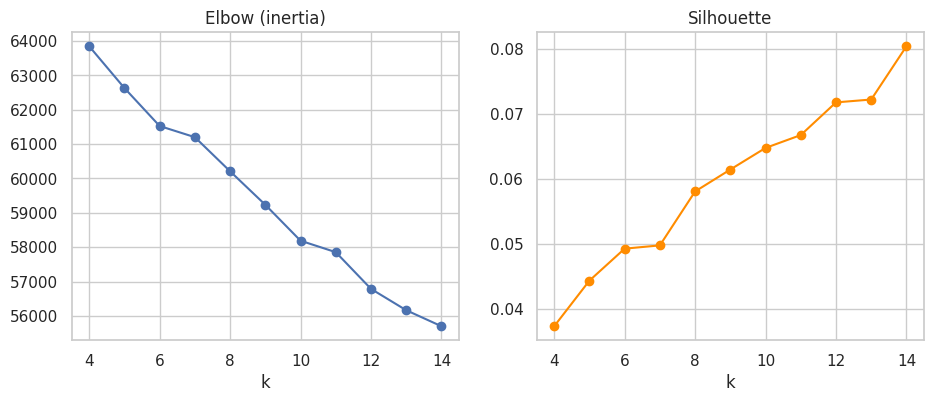

In [ ]:
N_LSA = 100
Z100 = normalize(Z[:, :N_LSA])           # L2-normalisasi -> mirip cosine k-means

rng = np.random.RandomState(RANDOM_STATE)
idx_s = rng.choice(len(Z100), size=min(6000, len(Z100)), replace=False)

ks = list(range(4, 15))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=5, random_state=RANDOM_STATE).fit(Z100)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z100[idx_s], km.labels_[idx_s]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ks, inertia, "o-"); axes[0].set_title("Elbow (inertia)"); axes[0].set_xlabel("k")
axes[1].plot(ks, sil, "o-", c="darkorange"); axes[1].set_title("Silhouette"); axes[1].set_xlabel("k")
plt.show()

## 6.3 K-Means dengan k = 9 (jumlah kategori asli) dan evaluasi terhadap label

Silhouette (sampel) : 0.0639
ARI                 : 0.0219
NMI                 : 0.0459
Homogeneity         : 0.0453
Completeness        : 0.0466


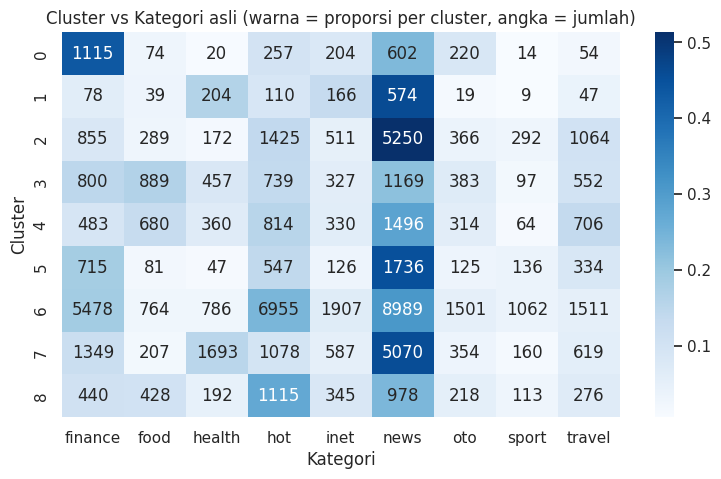

In [ ]:
K = y_train.nunique()
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Z100)
labels = km.labels_

print(f"Silhouette (sampel) : {silhouette_score(Z100[idx_s], labels[idx_s]):.4f}")
print(f"ARI                 : {adjusted_rand_score(y_train, labels):.4f}")
print(f"NMI                 : {normalized_mutual_info_score(y_train, labels):.4f}")
print(f"Homogeneity         : {homogeneity_score(y_train, labels):.4f}")
print(f"Completeness        : {completeness_score(y_train, labels):.4f}")

ct = pd.crosstab(pd.Series(labels, name="Cluster"), y_train.reset_index(drop=True).rename("Kategori"))
plt.figure(figsize=(9, 5))
sns.heatmap(ct.div(ct.sum(axis=1), axis=0), annot=ct.values, fmt="d", cmap="Blues")
plt.title("Cluster vs Kategori asli (warna = proporsi per cluster, angka = jumlah)")
plt.show()

In [ ]:
for c in range(K):
    members = np.where(labels == c)[0]
    mean_tfidf = np.asarray(Xtr_t[members].mean(axis=0)).ravel()
    top = vocab[mean_tfidf.argsort()[::-1][:10]]
    dom = ct.loc[c].idxmax()
    print(f"Cluster {c} (n={len(members):5d}, dominan: {dom:8s}) -> {', '.join(top)}")

Cluster 0 (n= 2560, dominan: finance ) -> rp, juta, 000, miliar, triliun, harga, di, ribu, tembus, dolar
Cluster 1 (n= 1246, dominan: news    ) -> covid, covid 19, 19, pandemi covid, 19 di, di, positif covid, pandemi, corona covid, untuk
Cluster 2 (n=10224, dominan: news    ) -> di, polisi, rumah, tewas, warga, di rumah, ada, ditangkap, banjir, jadi
Cluster 3 (n= 5413, dominan: news    ) -> ini, di, hari ini, hari, ini kata, kata, tahun, makanan, corona, bisa
Cluster 4 (n= 5247, dominan: news    ) -> yang, di, ini, yang bikin, bikin, corona, jadi, ada, foto, tak
Cluster 5 (n= 3847, dominan: news    ) -> ke, di, corona, ini, tak, yang, warga, ri, ihsg, polisi
Cluster 6 (n=28953, dominan: news    ) -> tak, dari, jadi, soal, dengan, untuk, saat, bisa, lagi, minta
Cluster 7 (n=11117, dominan: news    ) -> corona, virus, virus corona, di, positif, corona di, positif corona, pasien, kasus, pandemi corona
Cluster 8 (n= 4105, dominan: hot     ) -> dan, di, yang, ini, corona, cara, untuk, soal,

**Interpretasi:** K-Means (k=9) pada LSA-100 tidak selaras dengan kategori asli: silhouette 0,0639, ARI 0,0219, NMI 0,0459. Cluster lebih mencerminkan tema dan gaya penulisan, misalnya cluster 0 (rp, juta, miliar; dominan `finance`) dan cluster 1 serta 7 (tema COVID). Cluster 6 menampung 28.953 judul (sekitar 40%) dengan dominasi `news`. Kategori bukan struktur alami pada representasi ini, sehingga pendekatan supervised diperlukan.

## 6.4 Topic modelling dengan NMF

In [ ]:
nmf = NMF(n_components=K, init="nndsvda", random_state=RANDOM_STATE, max_iter=400)
W = nmf.fit_transform(Xtr_t)
for t, comp in enumerate(nmf.components_):
    print(f"Topik {t}: ", ", ".join(vocab[comp.argsort()[::-1][:10]]))

topic_assign = W.argmax(axis=1)
print("\nNMI topik NMF vs kategori:", round(normalized_mutual_info_score(y_train, topic_assign), 4))

Topik 0:  di, polisi, rumah, corona di, di rumah, indonesia, jakarta, di indonesia, jadi, di jakarta
Topik 1:  corona, virus, virus corona, positif, corona di, positif corona, kasus, pasien, meninggal, sembuh
Topik 2:  dari, rumah, lebih, dari rumah, china, dari corona, dapat, hingga, kerja, sembuh dari
Topik 3:  pandemi, tengah, di tengah, pandemi corona, corona, tengah pandemi, saat, saat pandemi, tengah corona, di
Topik 4:  19, covid, covid 19, untuk, pandemi covid, 19 di, positif covid, corona covid, pasien, pasien covid
Topik 5:  ini, hari, hari ini, kata, ini kata, tahun, bisa, makanan, saat, bikin
Topik 6:  ke, tak, soal, jokowi, rp, ada, minta, lagi, bisa, untuk
Topik 7:  yang, bikin, foto, jadi, yang bikin, yang bisa, yang tak, potret, fakta, galeri foto
Topik 8:  dan, cara, untuk, anak, foto, puasa, dengan, buka, rumah, 2020

NMI topik NMF vs kategori: 0.0426


**Interpretasi:** Topik NMF (NMI 0,0426 terhadap kategori) didominasi frasa tema pandemi (topik 1, 3, 4) dan pola kata umum, bukan sembilan kategori berita. Hasil ini konsisten dengan K-Means: struktur tanpa label tidak menggambarkan kategori.

## 6.5 Visualisasi 2D (t-SNE dari LSA) — warna kategori asli vs cluster

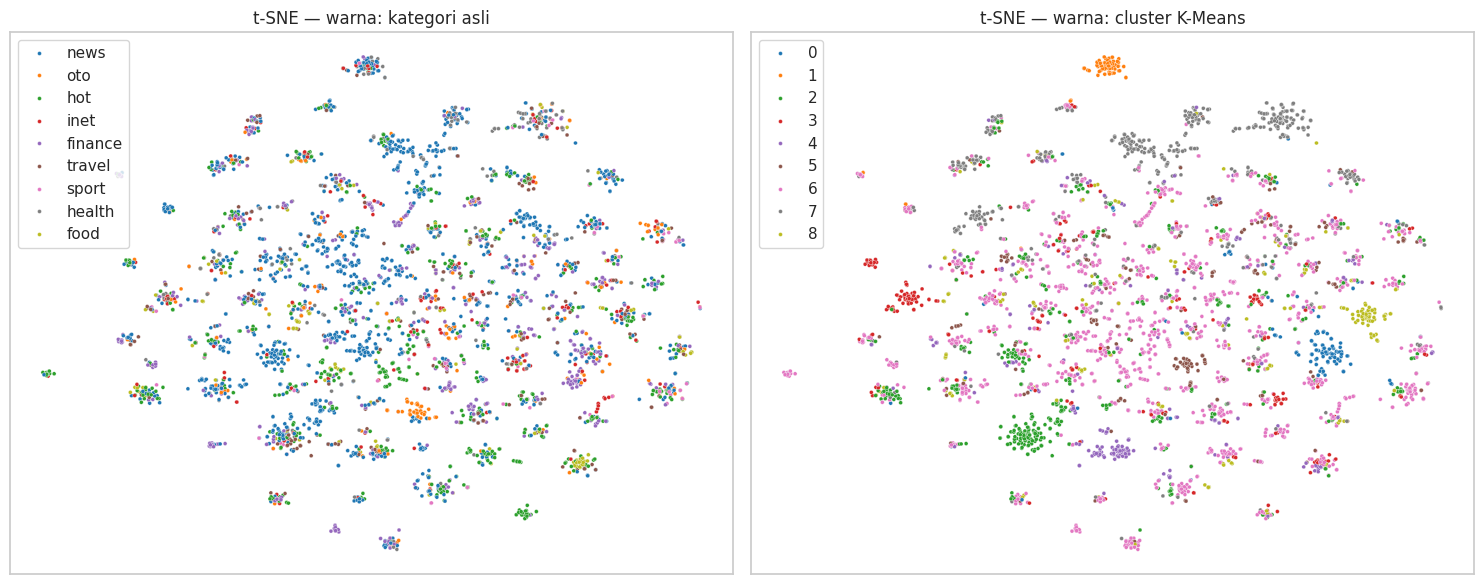

In [ ]:
idx_v = rng.choice(len(Z100), size=min(4000, len(Z100)), replace=False)
emb = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE).fit_transform(Z100[idx_v])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=y_train.values[idx_v], s=8, palette="tab10", ax=axes[0], legend="full")
axes[0].set_title("t-SNE — warna: kategori asli")
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=labels[idx_v], s=8, palette="tab10", ax=axes[1], legend="full")
axes[1].set_title("t-SNE — warna: cluster K-Means")
for a in axes: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 6.6 Dampak reduksi dimensi pada klasifikasi (supervised)
Membandingkan TF-IDF penuh vs LSA dengan berbagai jumlah komponen (LogReg, fit di train, evaluasi di test).

In [ ]:
rows = []
t0 = time.time()
full = Pipeline([("tfidf", make_tfidf()), ("clf", LogisticRegression(max_iter=1000, C=10))]).fit(X_train, y_train)
pr = full.predict(X_test)
rows.append({"Representasi": "TF-IDF penuh", "Dimensi": len(full.named_steps["tfidf"].vocabulary_),
             "Macro-F1": f1_score(y_test, pr, average="macro"), "Akurasi": accuracy_score(y_test, pr),
             "Waktu fit (s)": time.time() - t0})

for d in [50, 100, 200, 300]:
    t0 = time.time()
    p = Pipeline([("tfidf", make_tfidf()), ("svd", TruncatedSVD(d, random_state=RANDOM_STATE)),
                  ("norm", Normalizer()), ("clf", LogisticRegression(max_iter=1000, C=10))]).fit(X_train, y_train)
    pr = p.predict(X_test)
    rows.append({"Representasi": f"LSA-{d}", "Dimensi": d,
                 "Macro-F1": f1_score(y_test, pr, average="macro"), "Akurasi": accuracy_score(y_test, pr),
                 "Waktu fit (s)": time.time() - t0})

dr_df = pd.DataFrame(rows).round(4)
display(dr_df)
for _, r in dr_df.iterrows():
    log_result(6, f"LogReg + {r['Representasi']}", r["Macro-F1"], r["Akurasi"], f"dim={int(r['Dimensi'])}")

,Representasi,Dimensi,Macro-F1,Akurasi,Waktu fit (s)
0,TF-IDF penuh,5000,0.7821,0.8251,31.4324
1,LSA-50,50,0.4364,0.5715,21.4405
2,LSA-100,100,0.5298,0.6456,32.4744
3,LSA-200,200,0.6197,0.7017,46.2979
4,LSA-300,300,0.6660,0.7310,51.2514


[Pertemuan 6] LogReg + TF-IDF penuh: Macro-F1=0.7821, Akurasi=0.8251 (dim=5000)
[Pertemuan 6] LogReg + LSA-50: Macro-F1=0.4364, Akurasi=0.5715 (dim=50)
[Pertemuan 6] LogReg + LSA-100: Macro-F1=0.5298, Akurasi=0.6456 (dim=100)
[Pertemuan 6] LogReg + LSA-200: Macro-F1=0.6197, Akurasi=0.7017 (dim=200)
[Pertemuan 6] LogReg + LSA-300: Macro-F1=0.6660, Akurasi=0.7310 (dim=300)


**Interpretasi:** TF-IDF penuh (macro-F1 0,7821) jauh lebih baik daripada semua varian LSA: 0,4364 (50 komponen), 0,5298 (100), 0,6197 (200), dan 0,6660 (300). Semakin banyak komponen semakin baik, tetapi masih jauh di bawah TF-IDF penuh, sejalan dengan variansi yang hanya terjelaskan 30,6% pada 300 komponen. Reduksi dimensi dengan LSA tidak dipakai.

---
# PERTEMUAN 7 — Feature Selection, Diagnosis, dan Error Analysis (Bagian Matthew Rivandy, Oktapianus Zalukhu, Afni Titus Simanjuntak)
## 7.1 Feature selection: Chi-square (SelectKBest)
Seleksi fitur dilakukan **di dalam pipeline** (fit hanya pada fold latih).

Jumlah fitur TF-IDF penuh: 5000


,k fitur,F1 mean,F1 std,Acc mean,fit_time (s)
0,500,0.6528,0.0023,0.6638,4.6109
1,1000,0.7137,0.0028,0.7389,5.5328
2,2000,0.7527,0.0039,0.7892,5.9764
3,all,0.7738,0.0039,0.8165,6.5803


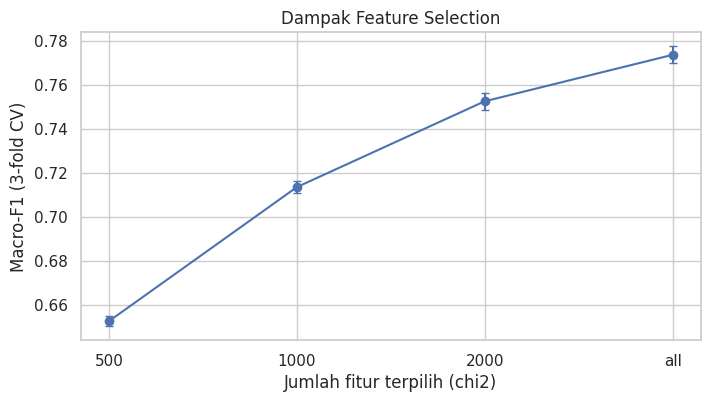

In [ ]:
n_feat_full = len(make_tfidf().fit(X_train).vocabulary_)
print("Jumlah fitur TF-IDF penuh:", n_feat_full)

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
ks_try = [k for k in [500, 1000, 2000, 5000, 10000, 20000, 40000] if k < n_feat_full] + ["all"]

fs_rows = []
for k in ks_try:
    steps = [("tfidf", make_tfidf())]
    if k != "all":
        steps.append(("sel", SelectKBest(chi2, k=k)))
    steps.append(("clf", LinearSVC(C=1.0)))
    s = cross_validate(Pipeline(steps), X_train, y_train, cv=cv3, scoring=scoring, n_jobs=-1)
    fs_rows.append({"k fitur": k, "F1 mean": s["test_f1m"].mean(), "F1 std": s["test_f1m"].std(),
                    "Acc mean": s["test_acc"].mean(), "fit_time (s)": s["fit_time"].mean()})
fs_df = pd.DataFrame(fs_rows).round(4)
display(fs_df)

x_lab = [str(k) for k in fs_df["k fitur"]]
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(x_lab, fs_df["F1 mean"], yerr=fs_df["F1 std"], marker="o", capsize=3)
ax.set_xlabel("Jumlah fitur terpilih (chi2)"); ax.set_ylabel("Macro-F1 (3-fold CV)"); ax.set_title("Dampak Feature Selection")
plt.show()

## 7.2 Feature selection berbasis model (L1) dan perbandingan

In [ ]:
l1_pipe = Pipeline([
    ("tfidf", make_tfidf()),
    ("sel", SelectFromModel(LinearSVC(penalty="l1", dual=False, C=0.3, max_iter=3000))),
    ("clf", LinearSVC(C=1.0)),
])
s = cross_validate(l1_pipe, X_train, y_train, cv=cv3, scoring=scoring, n_jobs=-1)
l1_pipe.fit(X_train, y_train)
n_l1 = int(l1_pipe.named_steps["sel"].get_support().sum())
print(f"L1-SelectFromModel : {n_l1} fitur | F1 = {s['test_f1m'].mean():.4f} ± {s['test_f1m'].std():.4f}")

best_k_row = fs_df.sort_values("F1 mean", ascending=False).iloc[0]
print(f"Chi2 terbaik       : k = {best_k_row['k fitur']} | F1 = {best_k_row['F1 mean']:.4f} ± {best_k_row['F1 std']:.4f}")

L1-SelectFromModel : 4496 fitur | F1 = 0.7737 ± 0.0036
Chi2 terbaik       : k = all | F1 = 0.7738 ± 0.0039


**Interpretasi:** Seleksi fitur chi-square tidak membantu: macro-F1 3-fold CV 0,6528 (k=500), 0,7137 (1000), 0,7527 (2000), dan 0,7738 (semua 5000 fitur). Seleksi L1 menyisakan 4.497 fitur dengan macro-F1 0,7738, sama dengan memakai semua fitur. Semakin banyak fitur semakin baik, konsisten dengan hasil ablation kosakata pada Bagian 3.

## 7.3 Fitur paling berpengaruh per kategori

In [ ]:
tf_full = make_tfidf()
Xf = tf_full.fit_transform(X_train)
vocab_f = np.array(tf_full.get_feature_names_out())
svc_full = LinearSVC(C=1.0).fit(Xf, y_train)

top_feat = {}
for i, c in enumerate(svc_full.classes_):
    top_feat[c] = list(vocab_f[svc_full.coef_[i].argsort()[::-1][:12]])
pd.DataFrame(top_feat).T.rename(columns=lambda i: f"#{i+1}")

,#1,#2,#3,#4,#5,#6,#7,#8,#9,#10,#11,#12
finance,ihsg,luhut,pinjol,erick,bahlil,bumn,cpns,pengusaha,investasi,jamsostek,ekonomi,saham
food,20detik,galeri foto,makanan,coffee,resto,galeri,resep,kue,makan,restoran,dimakan,renyah
health,bercinta,suspek,studi,who,kenali,odp dan,seks,persen,psikolog,olahraga,dokter,angkat bicara
hot,nia,fairuz,ashanty,manga,nikita,tayang,album,vicky,soraya,manggung,gisel,amanda
inet,oppo,samsung,huawei,whatsapp,apple,ponsel,vivo,5g,satelit,zoom,xiaomi,smartphone
news,kpk,mpr,transj,pdip,nurhadi,mahfud,menag,makassar,pks,medan,sulsel,kemenag
oto,mobil,toyota,otomotif,daihatsu,mitsubishi,honda,suzuki,nmax,nissan,suv,kia,motor
sport,olimpiade,khabib,mcgregor,pon,menpora,tontowi,gol,tyson,atlet,masters,pbsi,apriyani
travel,wisata,traveler,turis,paspor,traveling,kemenparekraf,destinasi,candi,pariwisata,wisatawan,hotel,taman


## 7.4 Diagnosis model: bias vs variance
* **Learning curve**: jika skor train jauh di atas validasi dan celah tidak menyempit saat data bertambah -> *high variance* (overfitting). Jika keduanya rendah dan berdekatan -> *high bias* (underfitting).
* **Validation curve** terhadap parameter regularisasi `C`.

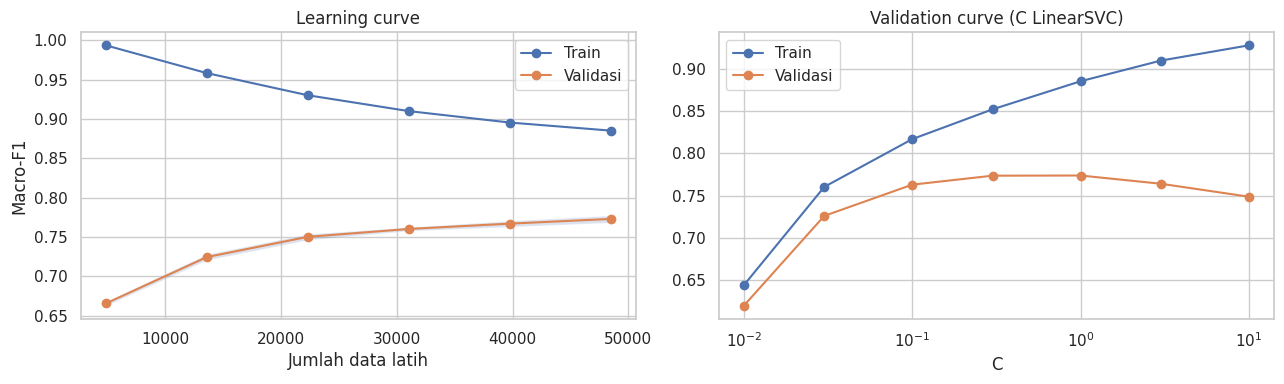

Train F1 = 0.8853 | Val F1 = 0.7730 | gap = 0.1123
Diagnosis awal: indikasi VARIANCE tinggi (overfit), pertimbangkan regularisasi lebih kuat / seleksi fitur / data lebih banyak


In [ ]:
diag_pipe = Pipeline([("tfidf", make_tfidf()), ("clf", LinearSVC(C=1.0))])
sizes, tr_sc, va_sc = learning_curve(diag_pipe, X_train, y_train, cv=cv3, scoring="f1_macro",
                                     train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(sizes, tr_sc.mean(1), "o-", label="Train"); axes[0].plot(sizes, va_sc.mean(1), "o-", label="Validasi")
axes[0].fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=0.2)
axes[0].set_title("Learning curve"); axes[0].set_xlabel("Jumlah data latih"); axes[0].set_ylabel("Macro-F1"); axes[0].legend()

C_range = [0.01, 0.03, 0.1, 0.3, 1, 3, 10]
tr_v, va_v = validation_curve(diag_pipe, X_train, y_train, param_name="clf__C", param_range=C_range,
                              cv=cv3, scoring="f1_macro", n_jobs=-1)
axes[1].semilogx(C_range, tr_v.mean(1), "o-", label="Train"); axes[1].semilogx(C_range, va_v.mean(1), "o-", label="Validasi")
axes[1].set_title("Validation curve (C LinearSVC)"); axes[1].set_xlabel("C"); axes[1].legend()
plt.tight_layout(); plt.show()

gap = tr_sc.mean(1)[-1] - va_sc.mean(1)[-1]
print(f"Train F1 = {tr_sc.mean(1)[-1]:.4f} | Val F1 = {va_sc.mean(1)[-1]:.4f} | gap = {gap:.4f}")
print("Diagnosis awal:", "indikasi VARIANCE tinggi (overfit), pertimbangkan regularisasi lebih kuat / seleksi fitur / data lebih banyak"
      if gap > 0.1 else "gap kecil: model cenderung BIAS-limited, perlu fitur/model lebih ekspresif atau label memang ambigu")

**Interpretasi:** Pada LinearSVC C=1,0, F1 latih 0,8853 sedangkan F1 validasi 0,7730 (gap 0,1123). Menurut aturan heuristik pada kode (gap > 0,1), model menunjukkan indikasi variance tinggi (overfitting moderat). Aturan ambang 0,1 hanyalah patokan sederhana, bukan kriteria baku.

## 7.5 Model terbaik sementara & error analysis
Model: TF-IDF (5000 fitur) + (SelectKBest chi2 terbaik dari 7.1) + LinearSVC. Karena hasil 7.1 menunjukkan memakai semua fitur terbaik (`k=all`), model ini identik dengan LinearSVC C=1,0 tanpa seleksi. Ini **bukan model final**; pemilihan model final dijadwalkan pada tahap UAS.

In [ ]:
best_k = best_k_row["k fitur"]
steps = [("tfidf", make_tfidf())]
if best_k != "all":
    steps.append(("sel", SelectKBest(chi2, k=int(best_k))))
steps.append(("clf", LinearSVC(C=1.0)))
final = Pipeline(steps).fit(X_train, y_train)

pred = final.predict(X_test)
f1m, acc = f1_score(y_test, pred, average="macro"), accuracy_score(y_test, pred)
print(f"TEST  macro-F1 = {f1m:.4f} | akurasi = {acc:.4f}\n")
print(classification_report(y_test, pred, digits=3))
log_result(7, f"TF-IDF + chi2(k={best_k}) + LinearSVC", f1m, acc, "model final")

TEST  macro-F1 = 0.7879 | akurasi = 0.8291

              precision    recall  f1-score   support

     finance      0.804     0.822     0.813      2828
        food      0.836     0.817     0.826       863
      health      0.728     0.668     0.697       983
         hot      0.849     0.884     0.866      3260
        inet      0.781     0.711     0.744      1126
        news      0.866     0.899     0.882      6466
         oto      0.829     0.731     0.777       875
       sport      0.842     0.700     0.765       487
      travel      0.738     0.704     0.721      1291

    accuracy                          0.829     18179
   macro avg      0.808     0.771     0.788     18179
weighted avg      0.828     0.829     0.828     18179

[Pertemuan 7] TF-IDF + chi2(k=all) + LinearSVC: Macro-F1=0.7879, Akurasi=0.8291 (model final)


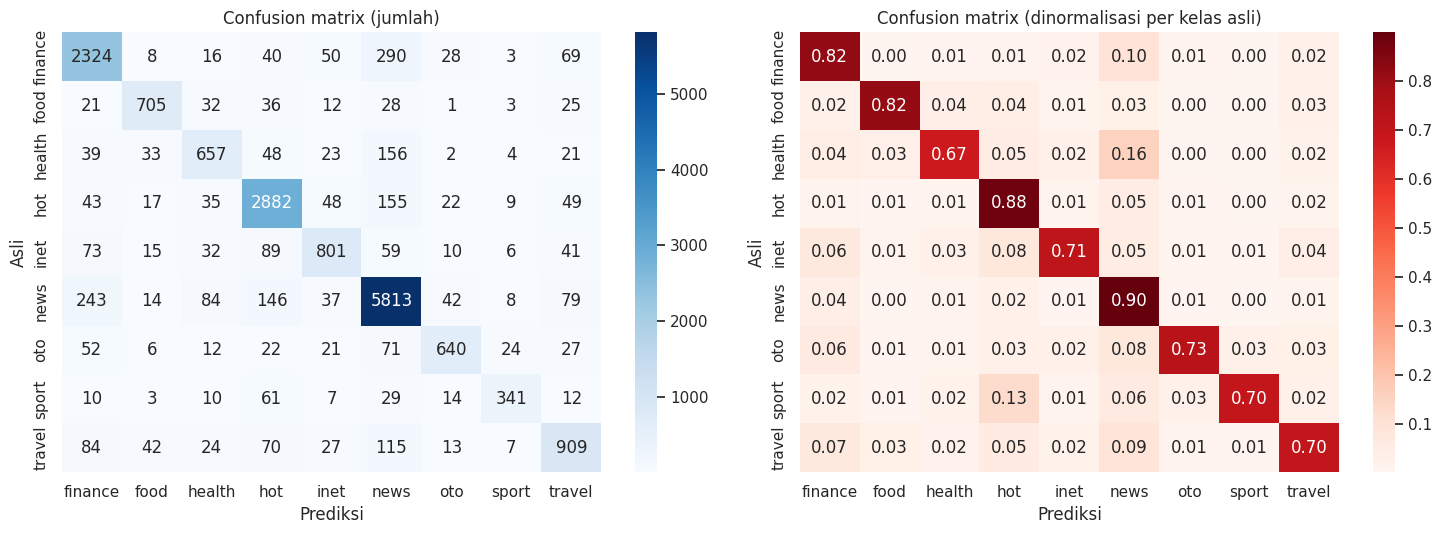

,Asli,Diprediksi,Jumlah
4,finance,news,290
40,news,finance,243
20,health,news,156
28,hot,news,155
43,news,hot,146
69,travel,news,115
35,inet,hot,89
42,news,health,84
64,travel,finance,84
47,news,travel,79


In [ ]:
classes = final.named_steps["clf"].classes_
cm = confusion_matrix(y_test, pred, labels=classes)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title("Confusion matrix (jumlah)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Reds", xticklabels=classes, yticklabels=classes, ax=axes[1])
axes[1].set_title("Confusion matrix (dinormalisasi per kelas asli)")
for a in axes: a.set_xlabel("Prediksi"); a.set_ylabel("Asli")
plt.tight_layout(); plt.show()

pairs = [(classes[i], classes[j], cm[i, j]) for i in range(len(classes)) for j in range(len(classes)) if i != j]
top_pairs = pd.DataFrame(pairs, columns=["Asli", "Diprediksi", "Jumlah"]).sort_values("Jumlah", ascending=False).head(10)
top_pairs

Error rate per kategori:
true
health     0.332
sport      0.300
travel     0.296
inet       0.289
oto        0.269
food       0.183
finance    0.178
hot        0.116
news       0.101
Name: correct, dtype: float64 



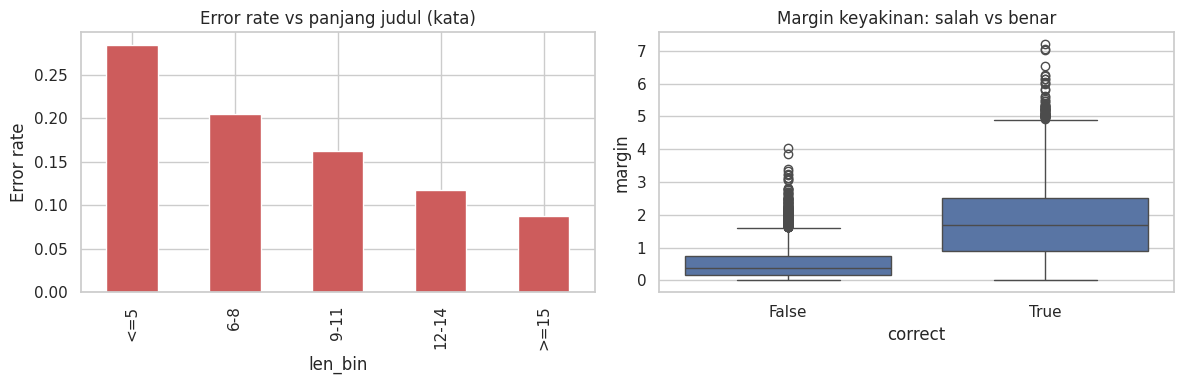

In [ ]:
err = pd.DataFrame({"Title": raw_test.values, "clean": X_test.values, "true": y_test.values, "pred": pred})
err["correct"] = err["true"] == err["pred"]
err["n_words"] = err["clean"].str.split().str.len()

dec = final.decision_function(X_test)
srt = np.sort(dec, axis=1)
err["margin"] = srt[:, -1] - srt[:, -2]

print("Error rate per kategori:")
print((1 - err.groupby("true")["correct"].mean()).round(3).sort_values(ascending=False), "\n")

err["len_bin"] = pd.cut(err["n_words"], bins=[0, 5, 8, 11, 14, 100], labels=["<=5", "6-8", "9-11", "12-14", ">=15"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(1 - err.groupby("len_bin")["correct"].mean()).plot.bar(ax=axes[0], color="indianred")
axes[0].set_title("Error rate vs panjang judul (kata)"); axes[0].set_ylabel("Error rate")

sns.boxplot(data=err, x="correct", y="margin", ax=axes[1]); axes[1].set_title("Margin keyakinan: salah vs benar")
plt.tight_layout(); plt.show()

In [ ]:
pd.set_option("display.max_colwidth", 110)
a, b = top_pairs.iloc[0]["Asli"], top_pairs.iloc[0]["Diprediksi"]
print(f"Contoh kesalahan: asli = {a}  ->  prediksi = {b}")
display(err[(err.true == a) & (err.pred == b)].sort_values("margin", ascending=False)[["Title", "true", "pred", "margin"]].head(15))

print("\nKesalahan dengan keyakinan TERTINGGI (kandidat label ambigu / noisy label):")
display(err[~err.correct].sort_values("margin", ascending=False)[["Title", "true", "pred", "margin"]].head(15))

Contoh kesalahan: asli = finance  ->  prediksi = news


,Title,true,pred,margin
8643,"Kejagung Tahan 6 Tersangka Jiwasraya, Andre: Hukum Tak Pandang Bulu",finance,news,4.051930
14694,Omnibus Law Dikhawatirkan Bernasib Serupa RUU KPK,finance,news,3.409660
9388,Momen Wali Kota Padang Sapa Anies 'Gubernur Indonesia',finance,news,2.689603
1199,Anggota DPRD DKI Ungkap Kejanggalan Kontraktor Proyek Monas,finance,news,2.641572
15158,"Tingkatkan Mutu, ASN KKP Diklat Online Lewat e-Milea",finance,news,2.523444
12485,Summarecon Jelaskan Tujuan Jokowi ke Bekasi,finance,news,2.469551
9854,Jurus Anies Hadapi Cuaca Ekstrem di DKI,finance,news,2.443961
9177,Jokowi Pastikan TKI yang Dipulangkan Dapat Bantuan Sosial,finance,news,2.348682
10363,"Ada KSBB, Lippo Kirim Sembako ke Pesantren dan Panti Asuhan DKI",finance,news,2.176305
2272,"Asabri Bantah Terjadi Suap, Mahfud Md Sebut Biarkan Hukum Berjalan",finance,news,2.170616



Kesalahan dengan keyakinan TERTINGGI (kandidat label ambigu / noisy label):


,Title,true,pred,margin
8643,"Kejagung Tahan 6 Tersangka Jiwasraya, Andre: Hukum Tak Pandang Bulu",finance,news,4.051930
4186,"Wali Kota Bogor Bima Arya Positif Corona, Diisolasi di RSUD Bogor",health,news,3.870518
14694,Omnibus Law Dikhawatirkan Bernasib Serupa RUU KPK,finance,news,3.409660
3972,Masak di Rumah Aja? Ini 3 Resep Makanan Sehat yang Bisa Dicoba,health,food,3.332768
5030,Perkenalkan Grandmaster Catur RI Novendra Priasmoro,sport,finance,3.239304
13334,BNPB Jamin Tempat Observasi WNI di Pulau Sebaru Lebih Baik dari Natuna,health,news,3.213716
2385,Cerita Wali Kota Bogor Bima Arya Soal Kondisinya Pasca Sembuh dari Corona,health,news,3.130655
10226,"Bidik 2,7 Juta Pengguna Mobile Banking",finance,inet,3.119857
10858,"Corona Jangkiti Pegawai Bank, Amankah Pegang Uang Kertas?",health,finance,3.053539
35,Pengusaha Muda Diminta Pacu Peningkatan Ekonomi Nasional,news,finance,3.053192


**Interpretasi:** Error rate per kategori tertinggi pada `health` (33,2%), `sport` (30,0%), `travel` (29,6%), dan `inet` (28,9%), terendah pada `news` (10,1%) dan `hot` (11,6%). Pasangan kesalahan terbanyak adalah `finance → news` (290), `news → finance` (243), `health → news` (156), dan `hot → news` (155). Contoh kesalahan dengan keyakinan tertinggi menunjukkan judul berlabel `finance` yang bertema politik/pemerintahan (Jiwasraya, Omnibus Law, Anies, Jokowi) serta judul `health` tentang COVID yang diprediksi `news` (mis. Wali Kota Bogor positif corona). Kesalahan seperti ini memperlihatkan label yang ambigu atau noisy, bukan semata kelemahan model.

---
## Referensi
- Ibrahim, I. *Indonesian News Title Dataset (detik.com)*. GitHub: https://github.com/ibamibrahim/dataset-judul-berita-indonesia
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.